In [2]:
import pandas as pd
import joblib 

In [3]:
!pip install xgboost

In [4]:
# Load external validation dataset
df_iol =  pd.read_csv(
    r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/df_iol_final.csv",
    low_memory=False)

In [5]:
df_iol.shape

(17850, 258)

In [6]:
# Load saved model 
model_path = r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/Original model/best_classifier_xgboost.clf"
model = joblib.load(model_path)

/opt/anaconda3/lib/python3.13/pickle.py:1760: UserWarning: [13:39:30] WARNING: /Users/runner/work/xgboost/xgboost/src/gbm/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


In [7]:
pipeline = r"/Users/nigus/Library/CloudStorage/OneDrive-MonashUniversity/PhD/CSAI validation/Original model/best_pipeline_xgboost.clf"
model_pipeline = joblib.load(pipeline)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RFECV from version 1.4.1.post1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.4.1.post1 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [8]:
print(type(model_pipeline))

<class 'sklearn.pipeline.Pipeline'>


In [9]:
print(model_pipeline.named_steps.keys())

dict_keys(['feature_selection', 'classification'])


In [10]:
rfecv = model_pipeline.named_steps["feature_selection"]

print(type(rfecv))
print("Number of selected features:", rfecv.n_features_)
print("Support mask:", rfecv.support_)
print("Ranking:", rfecv.ranking_)

<class 'sklearn.feature_selection._rfe.RFECV'>
Number of selected features: 10
Support mask: [ True  True False  True  True False  True False  True False False  True
  True  True  True False False False]
Ranking: [1 1 3 1 1 5 1 2 1 4 9 1 1 1 1 7 8 6]


In [11]:
print(hasattr(model_pipeline, "feature_names_in_"))
print(hasattr(rfecv, "feature_names_in_"))

True
True


In [12]:
print(model_pipeline.feature_names_in_)

['parity' 'gest_weeks' 'seifa' 'rurality' 'smoke_b20' 'smoke_a20'
 'pre_diab' 'pre_hyper' 'preeclampsia' 'gest_hyper' 'gest_diab' 'bmi'
 'mother_age' 'private_hospital' 'cob_region' 'gravidity'
 'gest_weeks_first_visit' 'num_ant_visit']


In [14]:
# Ensure compatibility of predictors in development model and validation dataset

## Rename some variables to match CSAI model
mapping = {
    'maternal_age': 'mother_age',
    'bmi_num': 'bmi',
    'rurality_2021_new': 'rurality',
    'parity_rec': 'parity',
    'birth_region': 'cob_region',
    'planned_ga': 'gest_weeks',
    'smoking_before_20w': 'smoke_b20',
    'dm': 'pre_diab',
    'birth_private_hospital': 'private_hospital'
}

# Remove duplicate columns 
df_iol = df_iol.loc[:, ~df_iol.columns.duplicated()]

df_iol = df_iol.rename(columns=mapping)

## Create missing variables
df_iol["gest_weeks_first_visit"] = 99

## ensure smoke_a20 exists
if "smoke_a20" not in df_iol.columns:
    df_iol["smoke_a20"] = 9   # or proper derived logic

# (ensure other derived vars exist if needed)
if "num_ant_visit" not in df_iol.columns:
    df_iol["num_ant_visit"] = 99

# 3. Force alignment to EXACT model schema
expected_cols = model_pipeline.feature_names_in_

X_val = df_iol.reindex(columns=expected_cols)

# 4. Now validate
assert list(X_val.columns) == list(expected_cols)

print("Schema match confirmed:", X_val.shape)
print(X_val.columns.tolist())

Schema match confirmed: (17850, 18)
['parity', 'gest_weeks', 'seifa', 'rurality', 'smoke_b20', 'smoke_a20', 'pre_diab', 'pre_hyper', 'preeclampsia', 'gest_hyper', 'gest_diab', 'bmi', 'mother_age', 'private_hospital', 'cob_region', 'gravidity', 'gest_weeks_first_visit', 'num_ant_visit']


In [15]:
# Handle level mismatches between current data and original model expectations

# 1. PARITY
df_iol['parity'] = df_iol['parity'].apply(lambda x: 0 if x == 0 else (1 if x >= 1 else 9))

# 2. GEST_WEEKS: Add missing category 99 for any potential missing values
df_iol['gest_weeks'] = df_iol['gest_weeks'].fillna(99)

# 3. SEIFA: Add missing category 9 for any potential missing values
df_iol['seifa'] = df_iol['seifa'].fillna(9)

# 4. RURALITY: convert to numeric
rurality_mapping = {
    'Major Cities of Australia': 1,
    'Inner Regional Australia': 2, 
    'Outer Regional Australia': 3,
    'Remote Australia': 4,
    'Very Remote Australia': 5
}
df_iol['rurality'] = df_iol['rurality'].map(rurality_mapping).fillna(9)

# 5. SMOKE_B20: Convert to numeric
smoke_b20_mapping = {
    'No': 0,
    'Yes': 1,
    'Unknown': 9
}
df_iol['smoke_b20'] = df_iol['smoke_b20'].map(smoke_b20_mapping).fillna(9)

# 7. BMI: Replace any missing values with 99
df_iol['bmi'] = df_iol['bmi'].fillna(99)

# 8. MOTHER_AGE: Replace any missing values with 99
df_iol['mother_age'] = df_iol['mother_age'].fillna(99)

# 9. PRIVATE_HOSPITAL: ensure missing values are coded as 9
df_iol['private_hospital'] = df_iol['private_hospital'].fillna(9)

# 10. COB_REGION: Replace NaN with 9
df_iol['cob_region'] = df_iol['cob_region'].fillna(9)

# 11. GRAVIDITY: Replace any missing values with 99  
df_iol['gravidity'] = df_iol['gravidity'].fillna(99)

# Verify the transformations
print("After level alignment:")
for col in ['parity', 'gest_weeks', 'seifa', 'rurality', 'smoke_b20', 'smoke_a20', 
           'pre_diab', 'pre_hyper', 'preeclampsia', 'gest_hyper', 'gest_diab',
           'private_hospital', 'cob_region']:
    print(f"{col}: {sorted(df_iol[col].unique())}")

After level alignment:
parity: [np.int64(0), np.int64(1)]
gest_weeks: [np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41)]
seifa: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
rurality: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
smoke_b20: [np.int64(0), np.int64(1), np.int64(9)]
smoke_a20: [np.int64(0), np.int64(1), np.int64(9)]
pre_diab: [np.int64(0), np.int64(1)]
pre_hyper: [np.int64(0), np.int64(1)]
preeclampsia: [np.int64(0), np.int64(1)]
gest_hyper: [np.int64(0), np.int64(1)]
gest_diab: [np.int64(0), np.int64(1)]
private_hospital: [np.int64(0)]
cob_region: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(9.0)]


In [16]:
# Assign all variables to X_val and check levels
X_val = df_iol[['parity', 'gest_weeks', 'seifa', 'rurality', 'smoke_b20', 'smoke_a20', 
                'pre_diab', 'pre_hyper', 'preeclampsia', 'gest_hyper', 'gest_diab',
                'bmi', 'mother_age', 'private_hospital', 'cob_region', 'gravidity',
                'gest_weeks_first_visit', 'num_ant_visit']]

# Print the levels/unique values for each variable
print("Current levels in X_val:")
print("=" * 50)

for col in X_val.columns:
    unique_vals = sorted(X_val[col].unique())
    print(f"{col}: {unique_vals}")
    
print("\n" + "=" * 50)
print(f"X_val shape: {X_val.shape}")
print(f"Columns: {list(X_val.columns)}")

# Check for any missing values
print(f"\nMissing values per column:")
print(X_val.isnull().sum())

Current levels in X_val:
parity: [np.int64(0), np.int64(1)]
gest_weeks: [np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41)]
seifa: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
rurality: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
smoke_b20: [np.int64(0), np.int64(1), np.int64(9)]
smoke_a20: [np.int64(0), np.int64(1), np.int64(9)]
pre_diab: [np.int64(0), np.int64(1)]
pre_hyper: [np.int64(0), np.int64(1)]
preeclampsia: [np.int64(0), np.int64(1)]
gest_hyper: [np.int64(0), np.int64(1)]
gest_diab: [np.int64(0), np.int64(1)]
bmi: [np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(

In [17]:
# Step 1: Ensure X_val matches the exact model schema
expected_cols = model_pipeline.feature_names_in_
X_val = X_val.reindex(columns=expected_cols)

# Verify schema alignment
assert list(X_val.columns) == list(expected_cols), "Column mismatch!"
print("✓ Schema alignment confirmed")
print(f"X_val shape: {X_val.shape}")

# Step 2: Check for missing values that might cause prediction errors
print(f"\nMissing values check:")
missing_counts = X_val.isnull().sum()
if missing_counts.sum() > 0:
    print("Missing values found:")
    print(missing_counts[missing_counts > 0])
else:
    print("✓ No missing values")

# Step 3: Make predictions
try:
    # Get probability predictions (if classification)
    y_pred_proba = model_pipeline.predict_proba(X_val)
    print(f"✓ Predictions successful - shape: {y_pred_proba.shape}")
    
    # Get class predictions (if classification)
    y_pred = model_pipeline.predict(X_val)
    print(f"✓ Class predictions successful - shape: {y_pred.shape}")
    
    # Display prediction summary
    print(f"\nPrediction Summary:")
    print(f"Predicted classes: {sorted(set(y_pred))}")
    print(f"Class distribution: {dict(zip(*np.unique(y_pred, return_counts=True)))}")
    
except Exception as e:
    print(f"Prediction failed: {e}")

# Step 4: If you have true labels (y_true), calculate performance metrics
# Uncomment and modify if you have ground truth labels:
"""
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Calculate metrics
print("\nPerformance Metrics:")
print(classification_report(y_true, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# AUC score (for binary classification)
if y_pred_proba.shape[1] == 2:
    auc = roc_auc_score(y_true, y_pred_proba[:, 1])
    print(f"AUC Score: {auc:.4f}")
"""

✓ Schema alignment confirmed
X_val shape: (17850, 18)

Missing values check:
✓ No missing values
✓ Predictions successful - shape: (17850, 2)
✓ Class predictions successful - shape: (17850,)

Prediction Summary:
Predicted classes: [np.int64(0), np.int64(1)]
Class distribution: {np.int64(0): np.int64(17291), np.int64(1): np.int64(559)}


'\nfrom sklearn.metrics import classification_report, confusion_matrix, roc_auc_score\n\n# Calculate metrics\nprint("\nPerformance Metrics:")\nprint(classification_report(y_true, y_pred))\nprint("\nConfusion Matrix:")\nprint(confusion_matrix(y_true, y_pred))\n\n# AUC score (for binary classification)\nif y_pred_proba.shape[1] == 2:\n    auc = roc_auc_score(y_true, y_pred_proba[:, 1])\n    print(f"AUC Score: {auc:.4f}")\n'

PIPELINE VALIDATION
pipeline predictions successful!
Input shape: (17850, 18)
Features used by pipeline: ['parity', 'gest_weeks', 'rurality', 'smoke_b20', 'pre_diab', 'preeclampsia', 'bmi', 'mother_age', 'private_hospital', 'cob_region']

Verification - Results match original model:
pipeline failed: name 'y_pred_original' is not defined

CORRECTED PIPELINE - MODEL PERFORMANCE EVALUATION
✓ Target variable found: {0: 13338, 1: 4512}

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.98      0.86     13338
           1       0.60      0.07      0.13      4512

    accuracy                           0.75     17850
   macro avg       0.68      0.53      0.49     17850
weighted avg       0.72      0.75      0.67     17850


Confusion Matrix:
[[13112   226]
 [ 4179   333]]
True Negatives: 13112, False Positives: 226
False Negatives: 4179, True Positives: 333

AUC Score: 0.7657


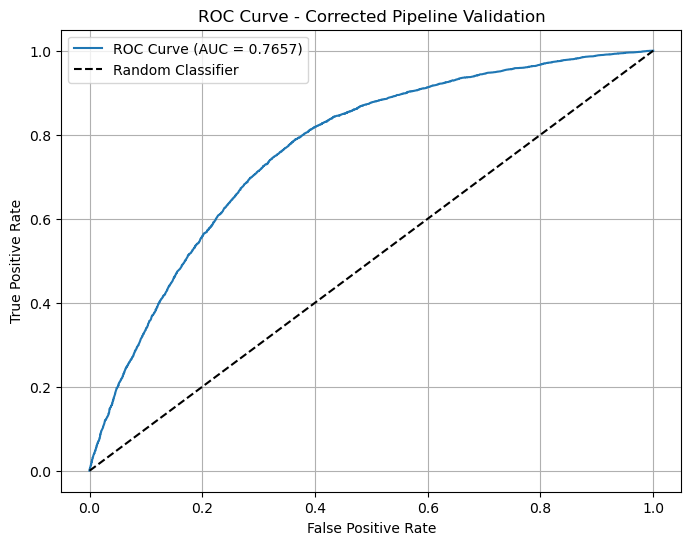


Actual vs Predicted Distribution:
Actual class distribution: {np.int64(0): np.int64(13338), np.int64(1): np.int64(4512)}
Predicted class distribution: {np.int64(0): np.int64(17291), np.int64(1): np.int64(559)}

Sample comparison (Actual vs Predicted):
   actual_outcome  predicted_class  predicted_probability
0               1                0               0.311574
1               0                1               0.511214
2               1                0               0.310397
3               0                0               0.104344
4               0                0               0.085454
5               0                0               0.329888
6               0                0               0.239967
7               1                0               0.472193
8               0                0               0.361096
9               0                0               0.346846

 pipeline validation completed!
Pipeline uses original 10 features as intended


In [18]:
# EVALUATION OF THE MODEL VALIDATION

# Create a custom pipeline that uses only the original 10 features

from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

# Step 1: Create a custom feature selector for the original 10 features
class OriginalFeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.original_features = [
            'parity', 'gest_weeks', 'rurality', 'smoke_b20', 'pre_diab',
            'preeclampsia', 'bmi', 'mother_age', 'private_hospital', 'cob_region'
        ]
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        # Select only the original 10 features
        return X[self.original_features]
    
    def get_feature_names_out(self, input_features=None):
        return self.original_features

# Step 2: Create a corrected pipeline using the original model
corrected_pipeline = Pipeline([
    ('feature_selection', OriginalFeatureSelector()),
    ('classification', model)  # Use the original XGBClassifier
])

print("PIPELINE VALIDATION")
print("="*50)

# Step 3: Test the corrected pipeline
try:
    # Use the full dataset (18 features) as input
    X_val_full = df_iol[['parity', 'gest_weeks', 'seifa', 'rurality', 'smoke_b20', 'smoke_a20',
                        'pre_diab', 'pre_hyper', 'preeclampsia', 'gest_hyper', 'gest_diab',
                        'bmi', 'mother_age', 'private_hospital', 'cob_region', 'gravidity',
                        'gest_weeks_first_visit', 'num_ant_visit']]
    
    # Pipeline will automatically select the 10 original features
    y_pred_corrected = corrected_pipeline.predict(X_val_full)
    y_pred_proba_corrected = corrected_pipeline.predict_proba(X_val_full)
    
    print("pipeline predictions successful!")
    print(f"Input shape: {X_val_full.shape}")
    print(f"Features used by pipeline: {corrected_pipeline.named_steps['feature_selection'].original_features}")
    
    # Verify it gives same results as original model
    print(f"\nVerification - Results match original model:")
    print(f"Predictions identical: {np.array_equal(y_pred_corrected, y_pred_original)}")
    print(f"Probabilities identical: {np.allclose(y_pred_proba_corrected, y_pred_proba_original)}")
    
except Exception as e:
    print(f"pipeline failed: {e}")

# Step 4: Now run your evaluation code with the corrected pipeline
if 'y_pred_corrected' in locals():
    # Replace the variable names 
    y_pred = y_pred_corrected
    y_pred_proba = y_pred_proba_corrected
    X_val = X_val_full  # Use full dataset as input
    
    print("\n" + "="*50)
    print("CORRECTED PIPELINE - MODEL PERFORMANCE EVALUATION")
    print("="*50)
    
    # The pipeline
    # Step 1: Target variable
    if 'cs_delivery' in df_iol.columns:
        y_true = df_iol['cs_delivery']
        print(f"✓ Target variable found: {y_true.value_counts().to_dict()}")
    
    # Step 2: Performance metrics
    from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
    import matplotlib.pyplot as plt
    
    # Classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    # Confusion Matrix
    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(cm)
    print(f"True Negatives: {cm[0,0]}, False Positives: {cm[0,1]}")
    print(f"False Negatives: {cm[1,0]}, True Positives: {cm[1,1]}")
    
    # AUC Score
    auc = roc_auc_score(y_true, y_pred_proba[:, 1])
    print(f"\nAUC Score: {auc:.4f}")
    
    # ROC Curve
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba[:, 1])
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.4f})')
    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - Corrected Pipeline Validation')
    plt.legend()
    plt.grid(True)
    plt.show()
    
    # Step 3: Distribution comparison
    print(f"\nActual vs Predicted Distribution:")
    print(f"Actual class distribution: {dict(zip(*np.unique(y_true, return_counts=True)))}")
    print(f"Predicted class distribution: {dict(zip(*np.unique(y_pred, return_counts=True)))}")
    
    # Step 4: Save results
    df_results = X_val.copy()
    df_results['actual_outcome'] = y_true
    df_results['predicted_class'] = y_pred
    df_results['predicted_probability'] = y_pred_proba[:, 1]
    
    print(f"\nSample comparison (Actual vs Predicted):")
    sample_results = df_results[['actual_outcome', 'predicted_class', 'predicted_probability']].head(10)
    print(sample_results)
    
    print(f"\n pipeline validation completed!")
    print(f"Pipeline uses original 10 features as intended")


C-section cases (n=4512): Mean risk = 0.328 ± 0.138
Vaginal delivery cases (n=13338): Mean risk = 0.182 ± 0.144


/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_20668/3279028215.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = ax2.boxplot(data_for_box, labels=labels_for_box, patch_artist=True)


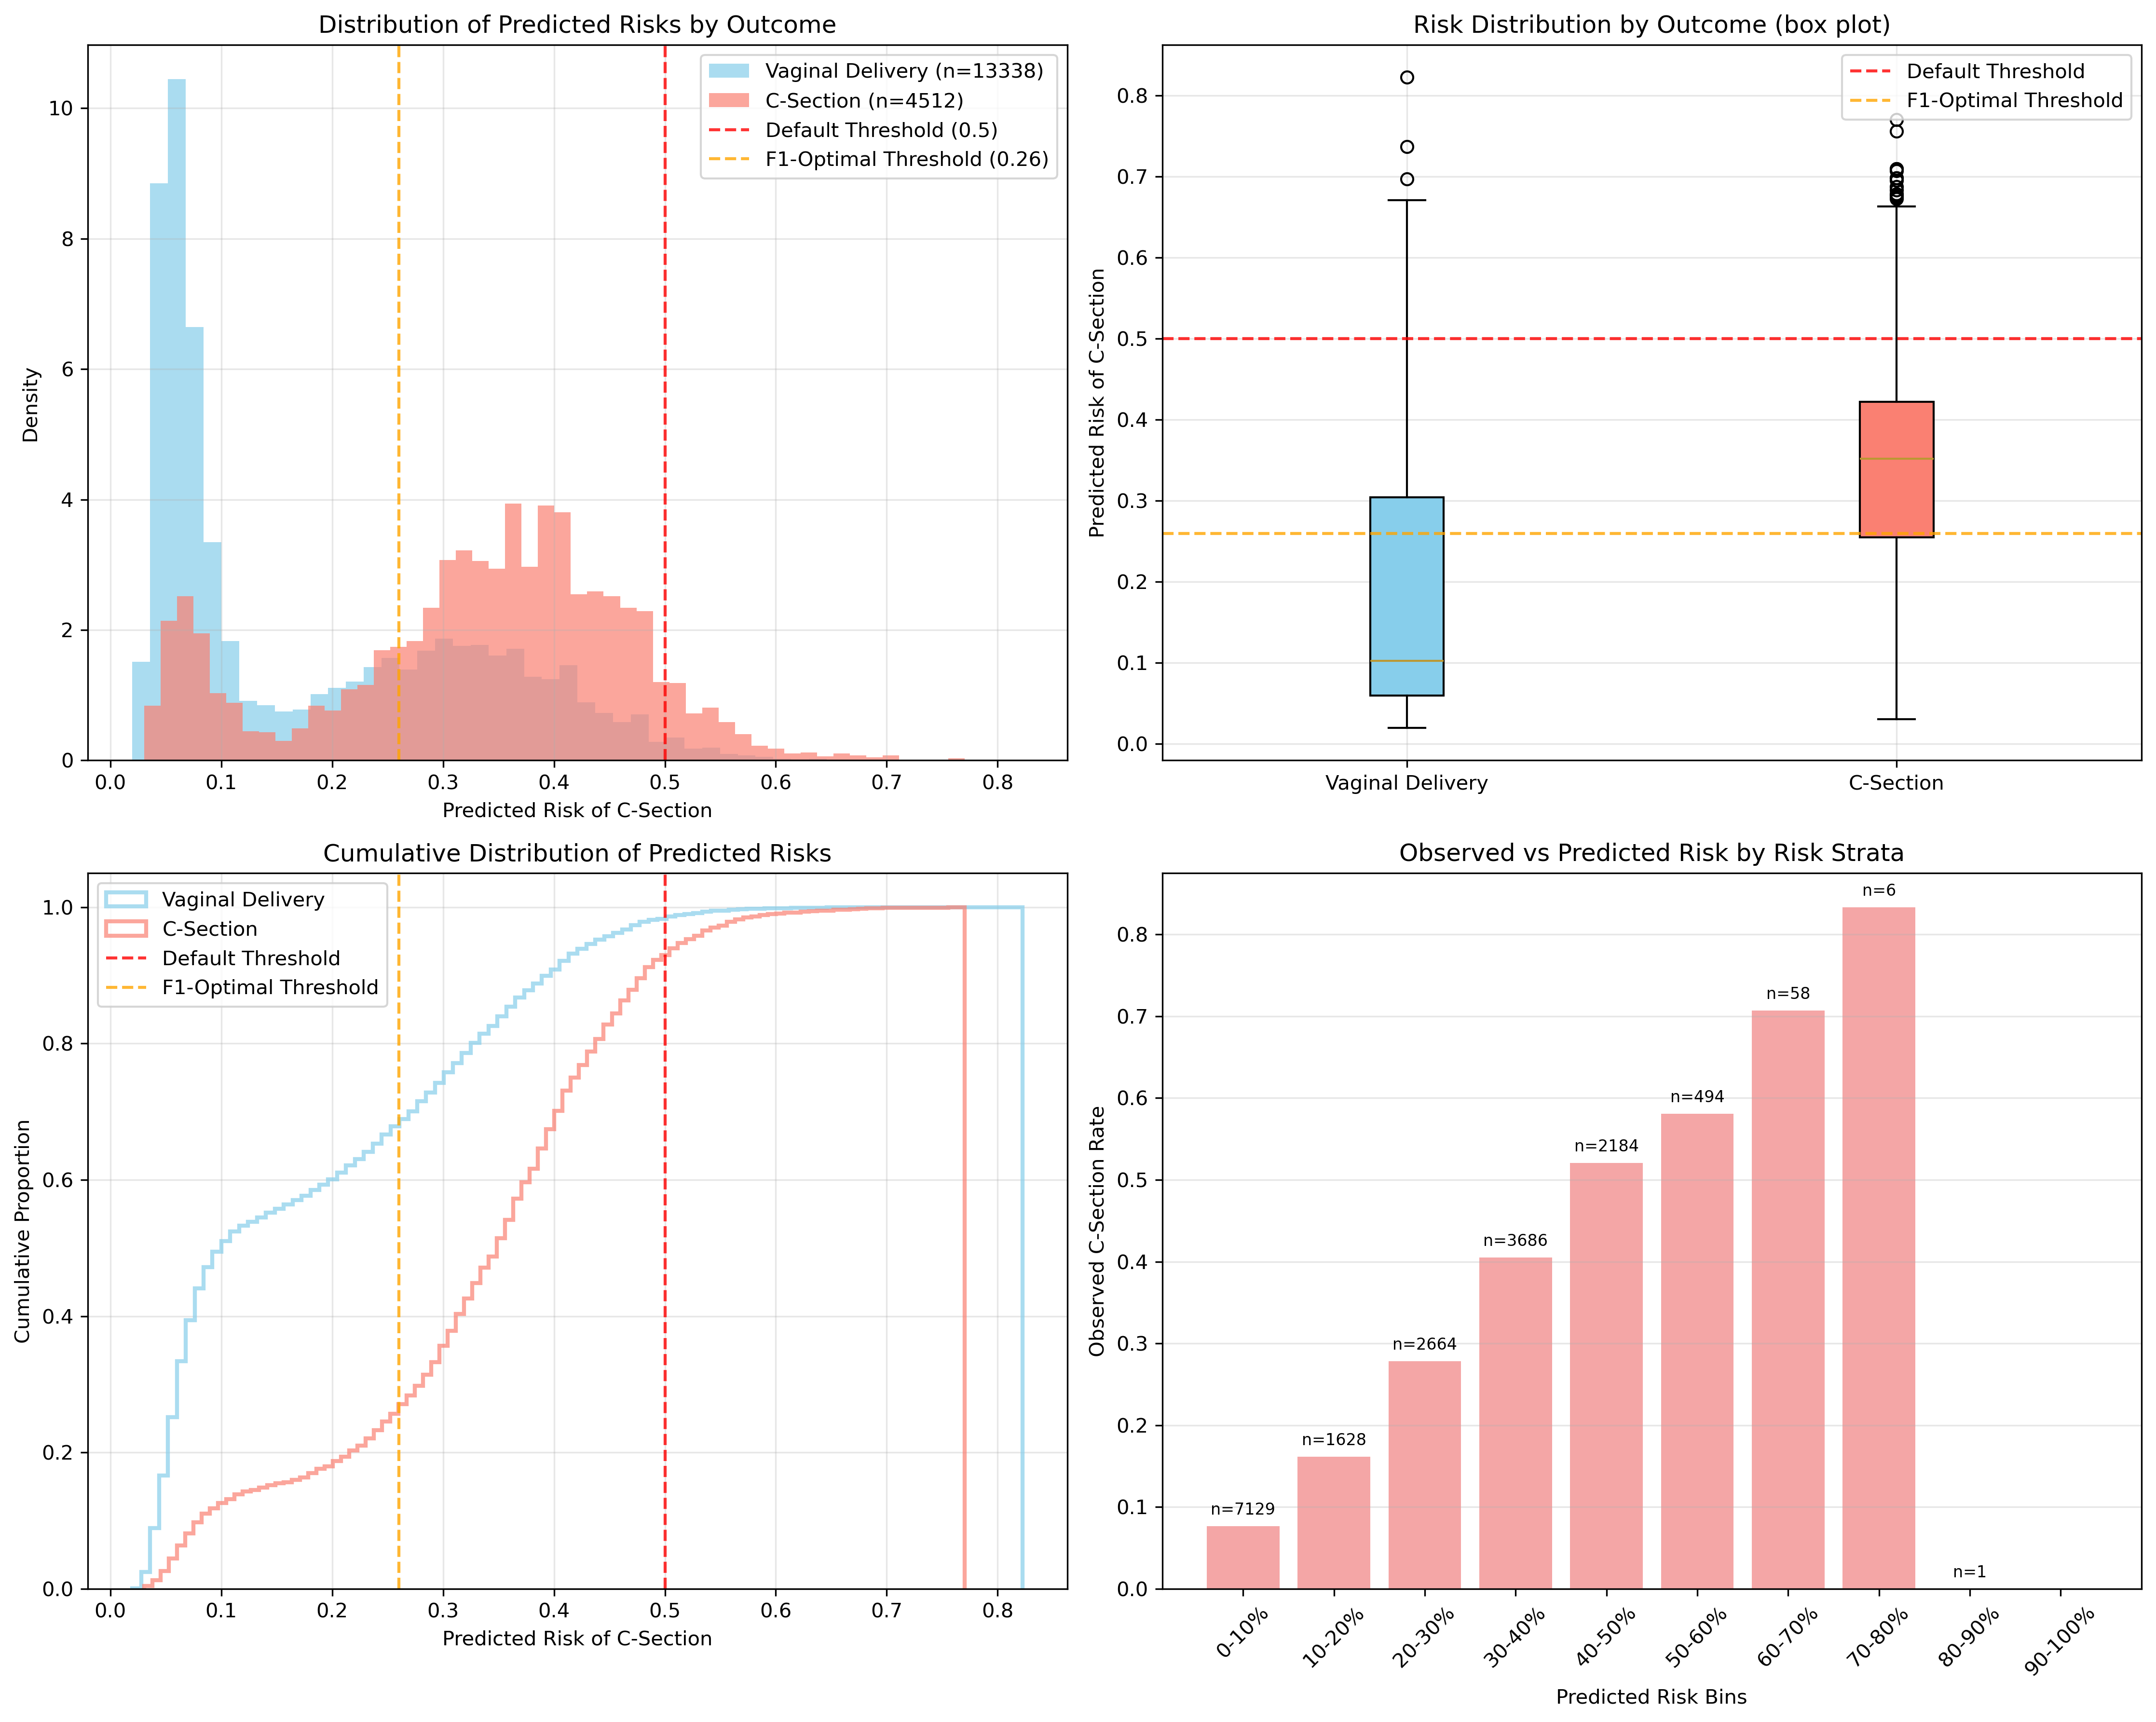


Risk Stratification Summary:
Low risk (<20%): 8,757 patients (49.1%)
Moderate risk (20-50%): 8,534 patients (47.8%)
High risk (≥50%): 559 patients (3.1%)

Threshold Analysis:
Threshold 0.10: 10,721 patients (60.1%), CS rate: 0.370
Threshold 0.20: 9,093 patients (50.9%), CS rate: 0.407
Threshold 0.26: 7,656 patients (42.9%), CS rate: 0.438
Threshold 0.30: 6,429 patients (36.0%), CS rate: 0.461
Threshold 0.40: 2,743 patients (15.4%), CS rate: 0.536
Threshold 0.50: 559 patients (3.1%), CS rate: 0.596


In [169]:
# DISTRIBUTION OF PREDICTED RISKS BY OUTCOME GROUP

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Get predicted probabilities for C-section (class 1)
predicted_risks = y_pred_proba[:, 1]

# Separate risks by actual outcome
cs_risks = predicted_risks[y_true == 1]  # C-section cases
vaginal_risks = predicted_risks[y_true == 0]  # Vaginal delivery cases

print(f"C-section cases (n={len(cs_risks)}): Mean risk = {cs_risks.mean():.3f} ± {cs_risks.std():.3f}")
print(f"Vaginal delivery cases (n={len(vaginal_risks)}): Mean risk = {vaginal_risks.mean():.3f} ± {vaginal_risks.std():.3f}")

# Create comprehensive visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Plot 1: Overlapping Histograms
ax1.hist(vaginal_risks, bins=50, alpha=0.7, label=f'Vaginal Delivery (n={len(vaginal_risks)})', 
         color='skyblue', density=True)
ax1.hist(cs_risks, bins=50, alpha=0.7, label=f'C-Section (n={len(cs_risks)})', 
         color='salmon', density=True)
ax1.axvline(x=0.5, color='red', linestyle='--', alpha=0.8, label='Default Threshold (0.5)')
ax1.axvline(x=0.260, color='orange', linestyle='--', alpha=0.8, label='F1-Optimal Threshold (0.26)')
ax1.set_xlabel('Predicted Risk of C-Section')
ax1.set_ylabel('Density')
ax1.set_title('Distribution of Predicted Risks by Outcome')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Box Plot Comparison
data_for_box = [vaginal_risks, cs_risks]
labels_for_box = ['Vaginal Delivery', 'C-Section']
box_plot = ax2.boxplot(data_for_box, labels=labels_for_box, patch_artist=True)
box_plot['boxes'][0].set_facecolor('skyblue')
box_plot['boxes'][1].set_facecolor('salmon')
ax2.axhline(y=0.5, color='red', linestyle='--', alpha=0.8, label='Default Threshold')
ax2.axhline(y=0.260, color='orange', linestyle='--', alpha=0.8, label='F1-Optimal Threshold')
ax2.set_ylabel('Predicted Risk of C-Section')
ax2.set_title('Risk Distribution by Outcome (box plot)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Cumulative Distribution
ax3.hist(vaginal_risks, bins=100, alpha=0.7, cumulative=True, density=True, 
         label='Vaginal Delivery', color='skyblue', histtype='step', linewidth=2)
ax3.hist(cs_risks, bins=100, alpha=0.7, cumulative=True, density=True, 
         label='C-Section', color='salmon', histtype='step', linewidth=2)
ax3.axvline(x=0.5, color='red', linestyle='--', alpha=0.8, label='Default Threshold')
ax3.axvline(x=0.260, color='orange', linestyle='--', alpha=0.8, label='F1-Optimal Threshold')
ax3.set_xlabel('Predicted Risk of C-Section')
ax3.set_ylabel('Cumulative Proportion')
ax3.set_title('Cumulative Distribution of Predicted Risks')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Risk Stratification Analysis
# Create risk bins
risk_bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
bin_labels = ['0-10%', '10-20%', '20-30%', '30-40%', '40-50%', 
              '50-60%', '60-70%', '70-80%', '80-90%', '90-100%']

# Calculate observed rates in each bin
observed_rates = []
bin_counts = []

for i in range(len(risk_bins)-1):
    mask = (predicted_risks >= risk_bins[i]) & (predicted_risks < risk_bins[i+1])
    if i == len(risk_bins)-2:  # Last bin includes upper bound
        mask = (predicted_risks >= risk_bins[i]) & (predicted_risks <= risk_bins[i+1])
    
    if mask.sum() > 0:
        observed_rate = y_true[mask].mean()
        observed_rates.append(observed_rate)
        bin_counts.append(mask.sum())
    else:
        observed_rates.append(0)
        bin_counts.append(0)

# Plot calibration-like analysis
# Fixed: Added the missing beginning of the bar plot function call
bars = ax4.bar(x_pos, observed_rates, alpha=0.7, color='lightcoral')
ax4.set_xlabel('Predicted Risk Bins')
ax4.set_ylabel('Observed C-Section Rate')
ax4.set_title('Observed vs Predicted Risk by Risk Strata')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(bin_labels, rotation=45)

# Add count labels on bars
for i, (bar, count) in enumerate(zip(bars, bin_counts)):
    if count > 0:
        # Fixed: Complete the text function call
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'n={count}', ha='center', va='bottom', fontsize=8)

ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()

# Save as high-resolution TIFF
plt.savefig('Predicted_risk_distribution_plots.tiff', 
            dpi=300,          
            format='tiff',     
            bbox_inches='tight', 
            facecolor='white',   
            edgecolor='none')
plt.show()

# Risk stratification summary
print(f"\nRisk Stratification Summary:")
print(f"Low risk (<20%): {(predicted_risks < 0.2).sum():,} patients ({(predicted_risks < 0.2).mean()*100:.1f}%)")
print(f"Moderate risk (20-50%): {((predicted_risks >= 0.2) & (predicted_risks < 0.5)).sum():,} patients ({((predicted_risks >= 0.2) & (predicted_risks < 0.5)).mean()*100:.1f}%)")
print(f"High risk (≥50%): {(predicted_risks >= 0.5).sum():,} patients ({(predicted_risks >= 0.5).mean()*100:.1f}%)")

# Threshold analysis
print(f"\nThreshold Analysis:")
for threshold in [0.1, 0.2, 0.26, 0.3, 0.4, 0.5]:
    high_risk = predicted_risks >= threshold  # Fixed: Ensured proper >= operator usage
    if high_risk.sum() > 0:
        # Fixed: Properly calculate the C-section rate for high-risk group
        cs_rate = y_true[high_risk].mean()
        # Fixed: Corrected indentation - removed extra spaces
        print(f"Threshold {threshold:.2f}: {high_risk.sum():,} patients ({high_risk.mean()*100:.1f}%), CS rate: {cs_rate:.3f}")
    else:
        print(f"Threshold {threshold:.2f}: No patients above threshold")

/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_20668/33750761.py:77: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp1 = axes[0,0].boxplot(parity_data, labels=parity_order, patch_artist=True)
/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_20668/33750761.py:106: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axes[0,1].boxplot(bmi_data, labels=bmi_order, patch_artist=True)
/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_20668/33750761.py:135: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp3 = axes[1,0].boxplot(age_data, labels=age_order, patch_artist=True)
/var/folders/z_/zldx_mr

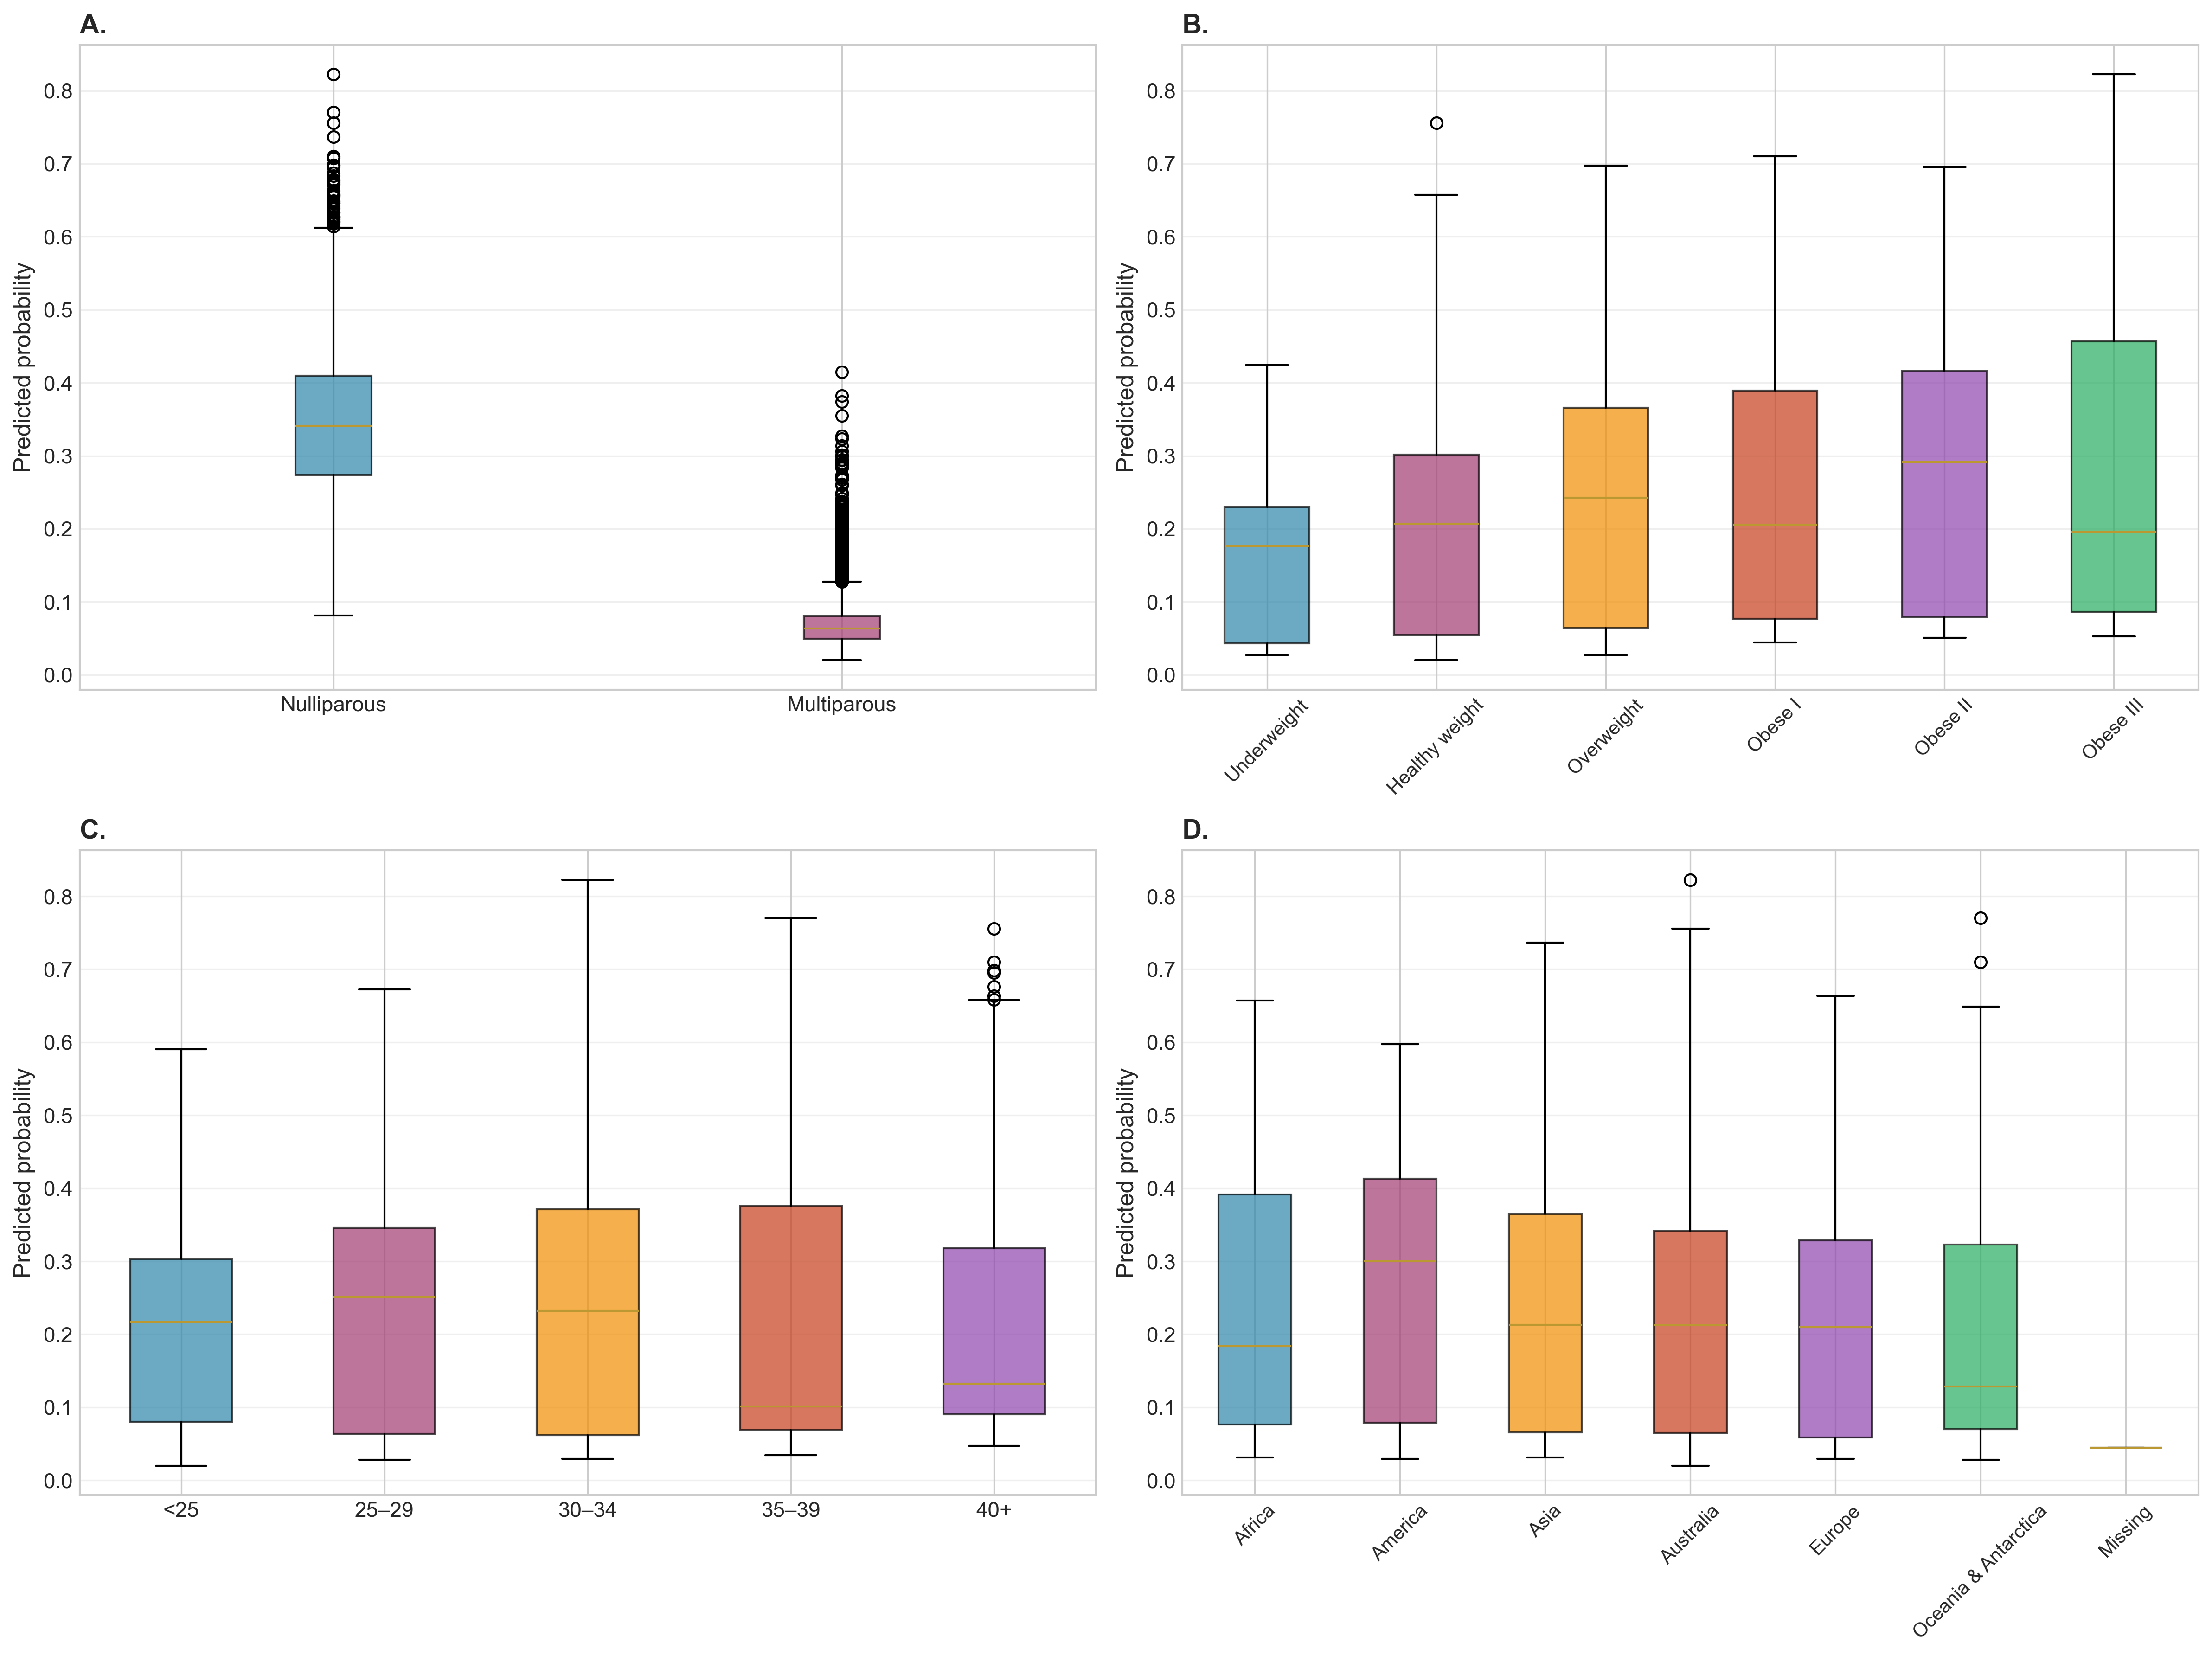

Summary of grouping variables:
Parity groups: Parity_group
Nulliparous    9681
Multiparous    8169
Name: count, dtype: int64

BMI groups: BMI_group
Healthy weight    6903
Overweight        5302
Obese I           2576
Obese II          1305
Obese III         1177
Underweight        587
Name: count, dtype: int64

Age groups: Age_group
30–34    6450
25–29    5222
35–39    3246
<25      2142
40+       789
Name: count, dtype: int64

Region groups: cob_region_label
Australia               7864
Asia                    7644
Africa                   790
Oceania & Antarctica     759
Europe                   642
America                  150
Missing                    1
Name: count, dtype: int64


In [183]:
# Distribution of predicted risks by sub-groups #

import pandas as pd
import matplotlib.pyplot as plt


# Create grouping variables

# WHO BMI categories
df_results['BMI_group'] = pd.cut(
    df_results['bmi'],
    bins=[0, 18.5, 25, 30, 35, 40, float('inf')],
    labels=[
        'Underweight',
        'Healthy weight',
        'Overweight',
        'Obese I',
        'Obese II',
        'Obese III'
    ],
    right=False
)

# Maternal age categories
df_results['Age_group'] = pd.cut(
    df_results['mother_age'],
    bins=[15, 25, 30, 35, 40, 60],
    labels=[
        '<25',
        '25–29',
        '30–34',
        '35–39',
        '40+'
    ],
    right=False
)

# Parity labels
parity_labels = {
    0: 'Nulliparous',
    1: 'Multiparous'
}

df_results['Parity_group'] = df_results['parity'].map(parity_labels)

# Country of birth labels - CORRECTED
region_labels = {
    1: 'Australia',
    2: 'Oceania & Antarctica',
    3: 'Europe',
    4: 'Africa',
    5: 'Asia',
    6: 'America',
    9: 'Missing'
}        
df_results['cob_region_label'] = df_results['cob_region'].map(region_labels)


# Set style for better appearance
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Define colors for consistency
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#8E44AD', '#27AE60', '#E74C3C']

# A. Parity
parity_order = ['Nulliparous', 'Multiparous']

parity_data = [
    df_results.loc[
        df_results['Parity_group'] == g,
        'predicted_probability'
    ].dropna()
    for g in parity_order
]

bp1 = axes[0,0].boxplot(parity_data, labels=parity_order, patch_artist=True)
# Color the boxes
for patch, color in zip(bp1['boxes'], colors[:len(parity_order)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[0,0].set_title("A.", loc="left", fontweight="bold", fontsize=14)
axes[0,0].set_ylabel("Predicted probability", fontsize=12)
axes[0,0].grid(axis='y', alpha=0.3)
axes[0,0].tick_params(axis='both', labelsize=11)

# B. BMI
bmi_order = [
    'Underweight',
    'Healthy weight',
    'Overweight',
    'Obese I',
    'Obese II',
    'Obese III'
]

bmi_data = [
    df_results.loc[
        df_results['BMI_group'] == g,
        'predicted_probability'
    ].dropna()
    for g in bmi_order
]

bp2 = axes[0,1].boxplot(bmi_data, labels=bmi_order, patch_artist=True)
# Color the boxes
for patch, color in zip(bp2['boxes'], colors[:len(bmi_order)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[0,1].set_title("B.", loc="left", fontweight="bold", fontsize=14)
axes[0,1].set_ylabel("Predicted probability", fontsize=12)
axes[0,1].tick_params(axis='x', rotation=45, labelsize=10)
axes[0,1].tick_params(axis='y', labelsize=11)
axes[0,1].grid(axis='y', alpha=0.3)

# C. Maternal age
age_order = [
    '<25',
    '25–29',
    '30–34',
    '35–39',
    '40+'
]

age_data = [
    df_results.loc[
        df_results['Age_group'] == g,
        'predicted_probability'
    ].dropna()
    for g in age_order
]

bp3 = axes[1,0].boxplot(age_data, labels=age_order, patch_artist=True)
# Color the boxes
for patch, color in zip(bp3['boxes'], colors[:len(age_order)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1,0].set_title("C.", loc="left", fontweight="bold", fontsize=14)
axes[1,0].set_ylabel("Predicted probability", fontsize=12)
axes[1,0].tick_params(axis='both', labelsize=11)
axes[1,0].grid(axis='y', alpha=0.3)

# D. Country of birth region 
# Filter out missing values and sort for consistent ordering
region_order = sorted([r for r in df_results['cob_region_label'].dropna().unique() if r != 'Missing'])
if 'Missing' in df_results['cob_region_label'].values:
    region_order.append('Missing')  # Add Missing at the end if it exists

region_data = [
    df_results.loc[
        df_results['cob_region_label'] == region,
        'predicted_probability'
    ].dropna()
    for region in region_order
]

bp4 = axes[1,1].boxplot(region_data, labels=region_order, patch_artist=True)
# Color the boxes
for patch, color in zip(bp4['boxes'], colors[:len(region_order)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

axes[1,1].set_title("D.", loc="left", fontweight="bold", fontsize=14)
axes[1,1].set_ylabel("Predicted probability", fontsize=12)
axes[1,1].tick_params(axis='x', rotation=45, labelsize=10)
axes[1,1].tick_params(axis='y', labelsize=11)
axes[1,1].grid(axis='y', alpha=0.3)

# Formatting and styling 
plt.tight_layout()

# Save 
plt.savefig(
    "Predicted_Risk_Subgroups.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Print summary statistics for verification

print("Summary of grouping variables:")
print(f"Parity groups: {df_results['Parity_group'].value_counts()}")
print(f"\nBMI groups: {df_results['BMI_group'].value_counts()}")
print(f"\nAge groups: {df_results['Age_group'].value_counts()}")
print(f"\nRegion groups: {df_results['cob_region_label'].value_counts()}")  

/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_20668/2817160978.py:11: RuntimeWarning: invalid value encountered in divide
  f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1])


Default threshold: 0.50
Optimal threshold (F1): 0.260
Recall-focused threshold: 0.059

COMPARISON OF DIFFERENT THRESHOLDS

ORIGINAL (threshold = 0.500):
----------------------------------------
Accuracy: 0.753
Precision (Class 1): 0.596
Recall (Class 1): 0.074
F1-score (Class 1): 0.131
Sensitivity: 0.074, Specificity: 0.983

F1-OPTIMAL (threshold = 0.260):
----------------------------------------
Accuracy: 0.694
Precision (Class 1): 0.438
Recall (Class 1): 0.743
F1-score (Class 1): 0.551
Sensitivity: 0.743, Specificity: 0.677

RECALL-FOCUSED (threshold = 0.059):
----------------------------------------
Accuracy: 0.424
Precision (Class 1): 0.300
Recall (Class 1): 0.959
F1-score (Class 1): 0.457
Sensitivity: 0.959, Specificity: 0.243


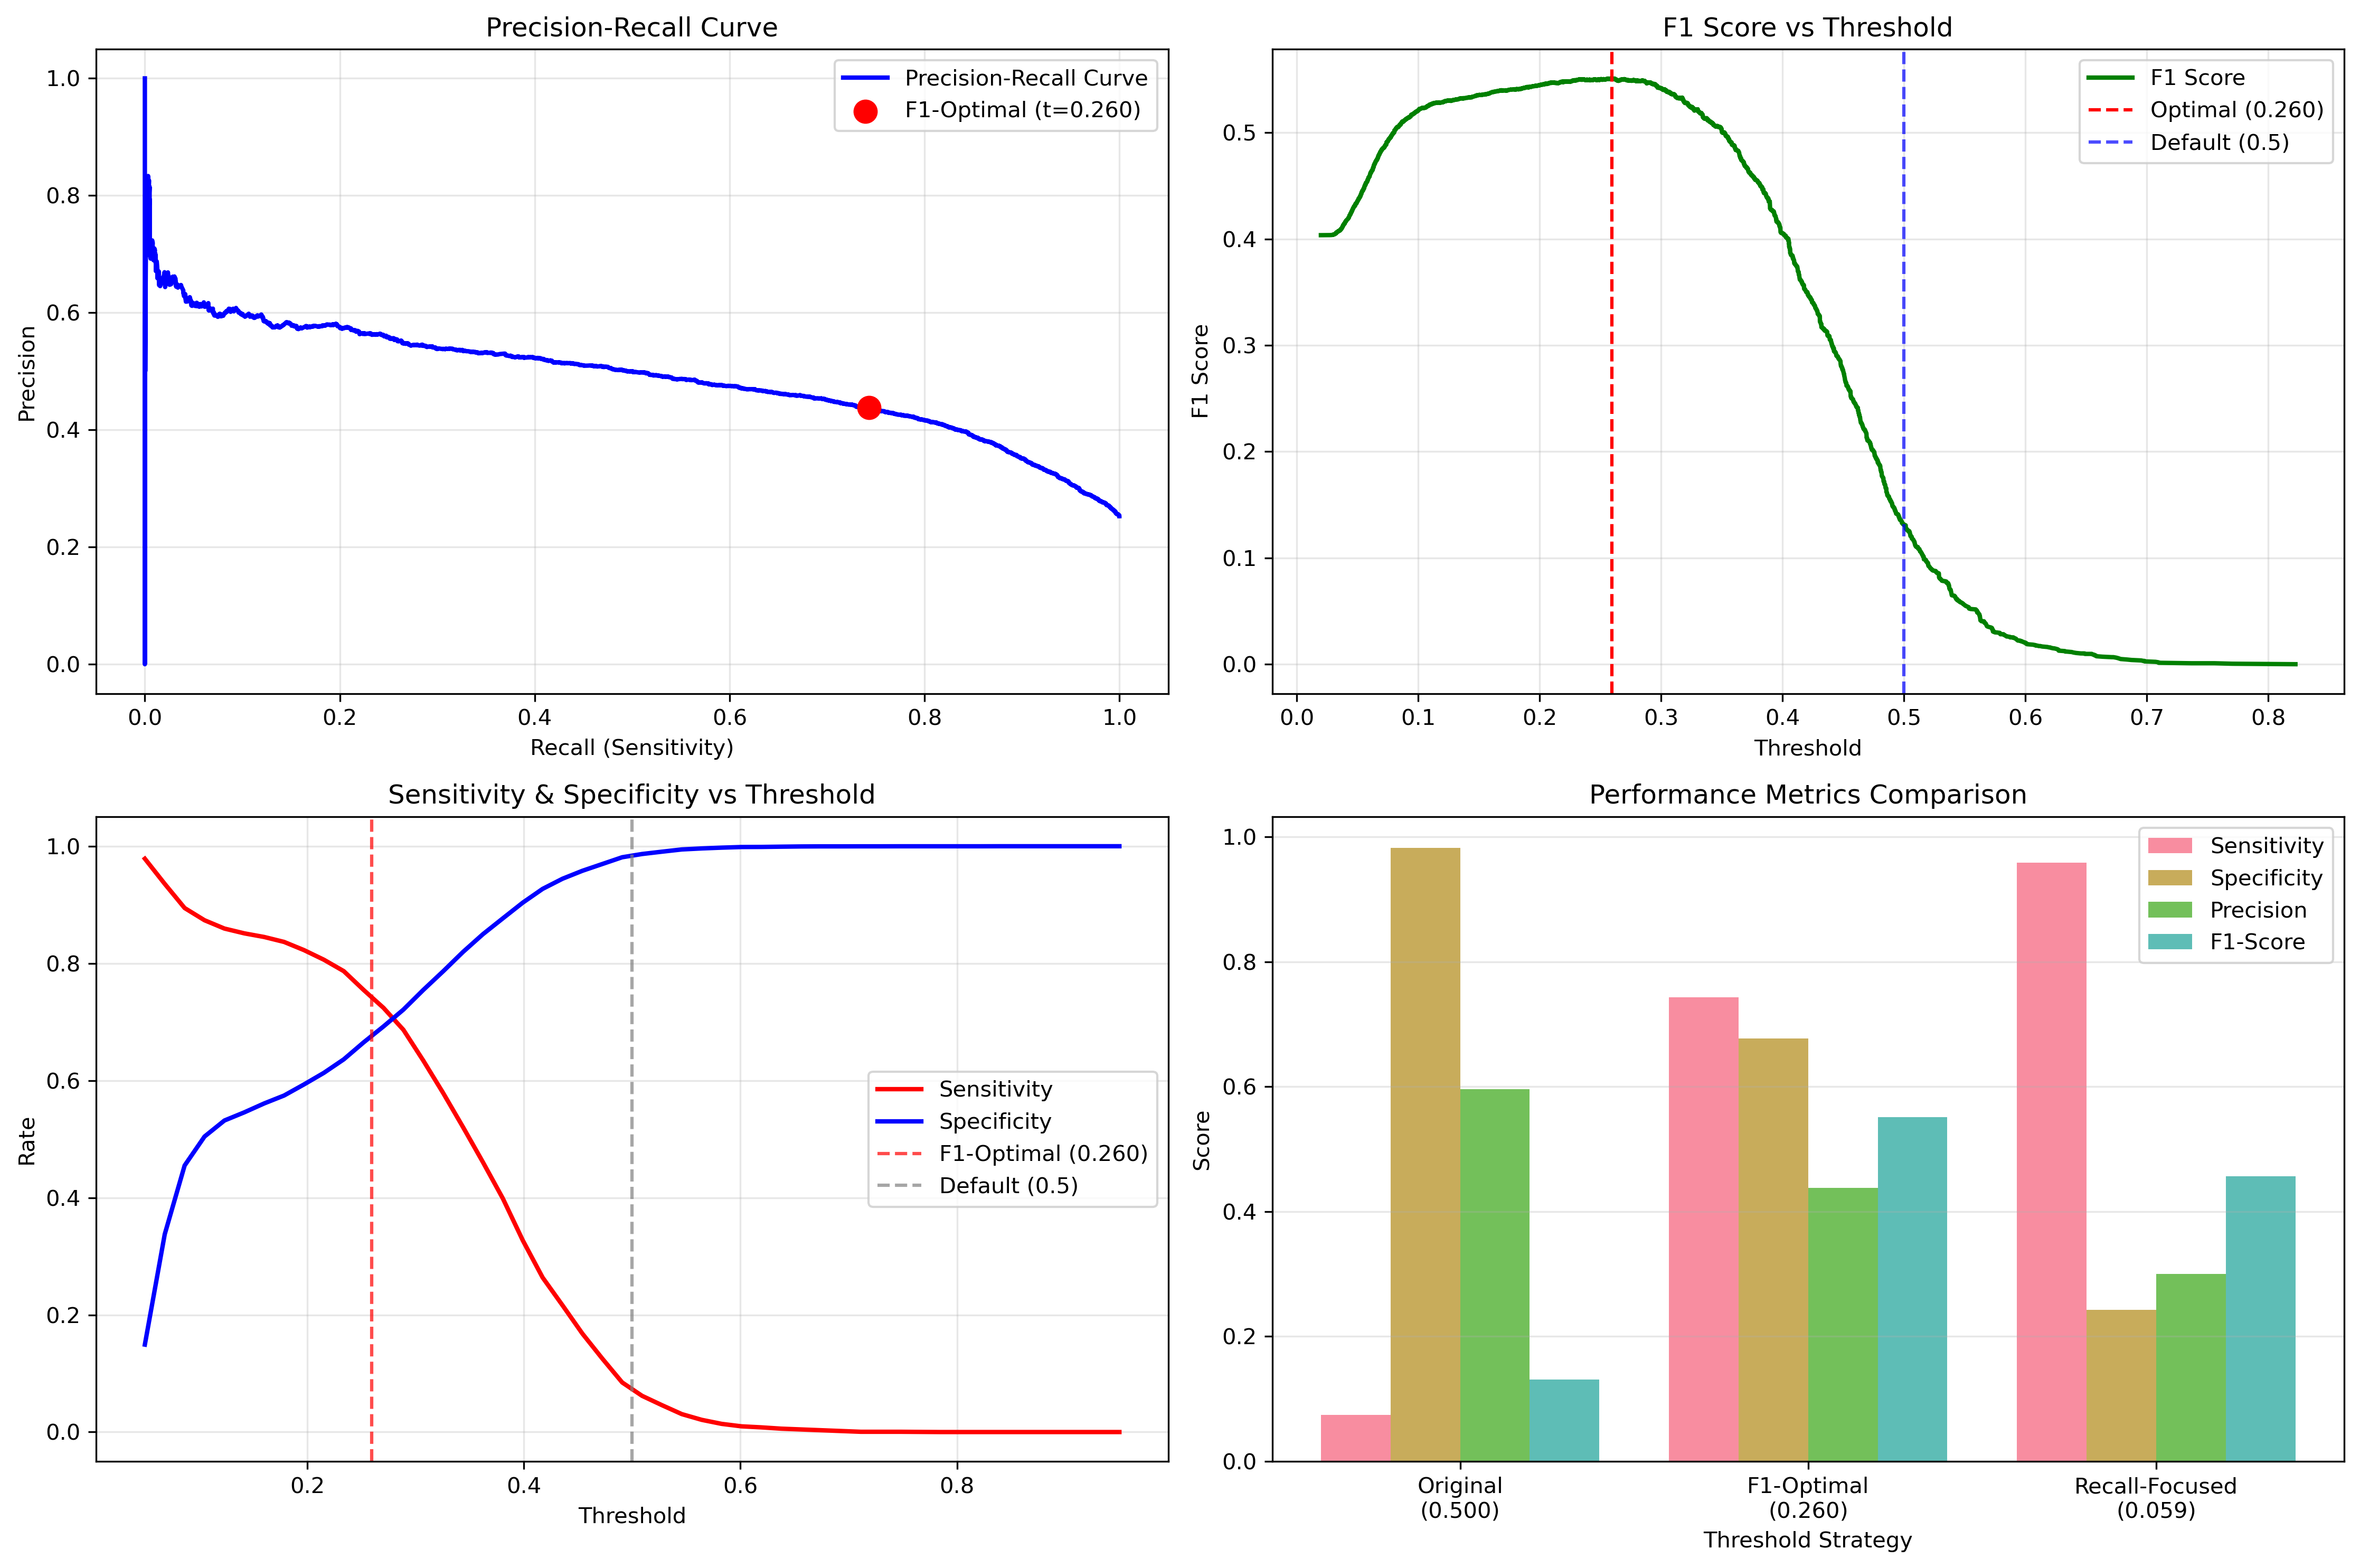

In [154]:
# OPTIMAL THRESHOLD ANALYSIS AND ADJUSTMENT

from sklearn.metrics import precision_recall_curve, f1_score, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Calculate precision-recall curve and find optimal thresholds
precision, recall, thresholds = precision_recall_curve(y_true, y_pred_proba[:, 1])

# Calculate F1 scores for each threshold
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1])
f1_scores = np.nan_to_num(f1_scores)  # Handle division by zero

# Find optimal threshold based on F1 score
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]
optimal_f1 = f1_scores[optimal_idx]

# Find recall-focused threshold (precision >= 0.3)
min_precision = 0.3
valid_indices = precision[:-1] >= min_precision
if np.any(valid_indices):
    recall_focused_idx = np.argmax(recall[:-1][valid_indices])
    actual_indices = np.where(valid_indices)[0]
    recall_focused_threshold = thresholds[actual_indices[recall_focused_idx]]
else:
    recall_focused_threshold = optimal_threshold

print(f"Default threshold: 0.50")
print(f"Optimal threshold (F1): {optimal_threshold:.3f}")
print(f"Recall-focused threshold: {recall_focused_threshold:.3f}")

# Step 2: Apply different thresholds and compare
y_pred_original = (y_pred_proba[:, 1] >= 0.5).astype(int)
y_pred_f1_optimal = (y_pred_proba[:, 1] >= optimal_threshold).astype(int)
y_pred_recall_focused = (y_pred_proba[:, 1] >= recall_focused_threshold).astype(int)

# Function to print metrics
def print_metrics(y_true, y_pred, name, threshold):
    print(f"\n{name} (threshold = {threshold:.3f}):")
    print("-" * 40)
    report = classification_report(y_true, y_pred, output_dict=True)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    print(f"Accuracy: {report['accuracy']:.3f}")
    print(f"Precision (Class 1): {report['1']['precision']:.3f}")
    print(f"Recall (Class 1): {report['1']['recall']:.3f}")
    print(f"F1-score (Class 1): {report['1']['f1-score']:.3f}")
    print(f"Sensitivity: {tp/(tp+fn):.3f}, Specificity: {tn/(tn+fp):.3f}")

# Compare all approaches
print("\n" + "="*50)
print("COMPARISON OF DIFFERENT THRESHOLDS")
print("="*50)

print_metrics(y_true, y_pred_original, "ORIGINAL", 0.5)
print_metrics(y_true, y_pred_f1_optimal, "F1-OPTIMAL", optimal_threshold)
print_metrics(y_true, y_pred_recall_focused, "RECALL-FOCUSED", recall_focused_threshold)

# Step 3: Visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Precision-Recall Curve
ax1.plot(recall, precision, 'b-', linewidth=2, label='Precision-Recall Curve')
ax1.scatter(recall[:-1][optimal_idx], precision[:-1][optimal_idx], 
           color='red', s=100, label=f'F1-Optimal (t={optimal_threshold:.3f})', zorder=5)
ax1.set_xlabel('Recall (Sensitivity)')
ax1.set_ylabel('Precision')
ax1.set_title('Precision-Recall Curve')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: F1 Score vs Threshold
ax2.plot(thresholds, f1_scores, 'g-', linewidth=2, label='F1 Score')
ax2.axvline(x=optimal_threshold, color='red', linestyle='--', 
           label=f'Optimal ({optimal_threshold:.3f})')
ax2.axvline(x=0.5, color='blue', linestyle='--', alpha=0.7, label='Default (0.5)')
ax2.set_xlabel('Threshold')
ax2.set_ylabel('F1 Score')
ax2.set_title('F1 Score vs Threshold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Sensitivity and Specificity vs Threshold
thresholds_range = np.linspace(0.05, 0.95, 50)
sensitivities = []
specificities = []

for thresh in thresholds_range:
    y_pred_temp = (y_pred_proba[:, 1] >= thresh).astype(int)
    cm_temp = confusion_matrix(y_true, y_pred_temp)
    tn, fp, fn, tp = cm_temp.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    sensitivities.append(sensitivity)
    specificities.append(specificity)

ax3.plot(thresholds_range, sensitivities, 'r-', linewidth=2, label='Sensitivity')
ax3.plot(thresholds_range, specificities, 'b-', linewidth=2, label='Specificity')
ax3.axvline(x=optimal_threshold, color='red', linestyle='--', alpha=0.7, 
           label=f'F1-Optimal ({optimal_threshold:.3f})')
ax3.axvline(x=0.5, color='gray', linestyle='--', alpha=0.7, label='Default (0.5)')
ax3.set_xlabel('Threshold')
ax3.set_ylabel('Rate')
ax3.set_title('Sensitivity & Specificity vs Threshold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Threshold Comparison Bar Chart
thresholds_names = ['Original\n(0.500)', f'F1-Optimal\n({optimal_threshold:.3f})', 
                   f'Recall-Focused\n({recall_focused_threshold:.3f})']
metrics_data = {
    'Sensitivity': [0.074, 0.743, 0.959],  
    'Specificity': [0.983, 0.677, 0.243],
    'Precision': [0.596, 0.438, 0.300],
    'F1-Score': [0.131, 0.551, 0.457]
}

x = np.arange(len(thresholds_names))
width = 0.2

for i, (metric, values) in enumerate(metrics_data.items()):
    ax4.bar(x + i*width, values, width, label=metric, alpha=0.8)

ax4.set_xlabel('Threshold Strategy')
ax4.set_ylabel('Score')
ax4.set_title('Performance Metrics Comparison')
ax4.set_xticks(x + width * 1.5)
ax4.set_xticklabels(thresholds_names)
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

FEATURE IMPORTANCE
Number of features: 10
Feature importance shape: (10,)
---------------------------------------------
Feature              Importance   Percentage
---------------------------------------------
 1. parity              0.8610       86.1%
 2. bmi                 0.0290        2.9%
 3. mother_age          0.0223        2.2%
 4. pre_diab            0.0219        2.2%
 5. gest_weeks          0.0175        1.8%
 6. cob_region          0.0129        1.3%
 7. preeclampsia        0.0105        1.1%
 8. private_hospital    0.0101        1.0%
 9. smoke_b20           0.0082        0.8%
10. rurality            0.0066        0.7%
---------------------------------------------
Total                  1.0000      100.0%


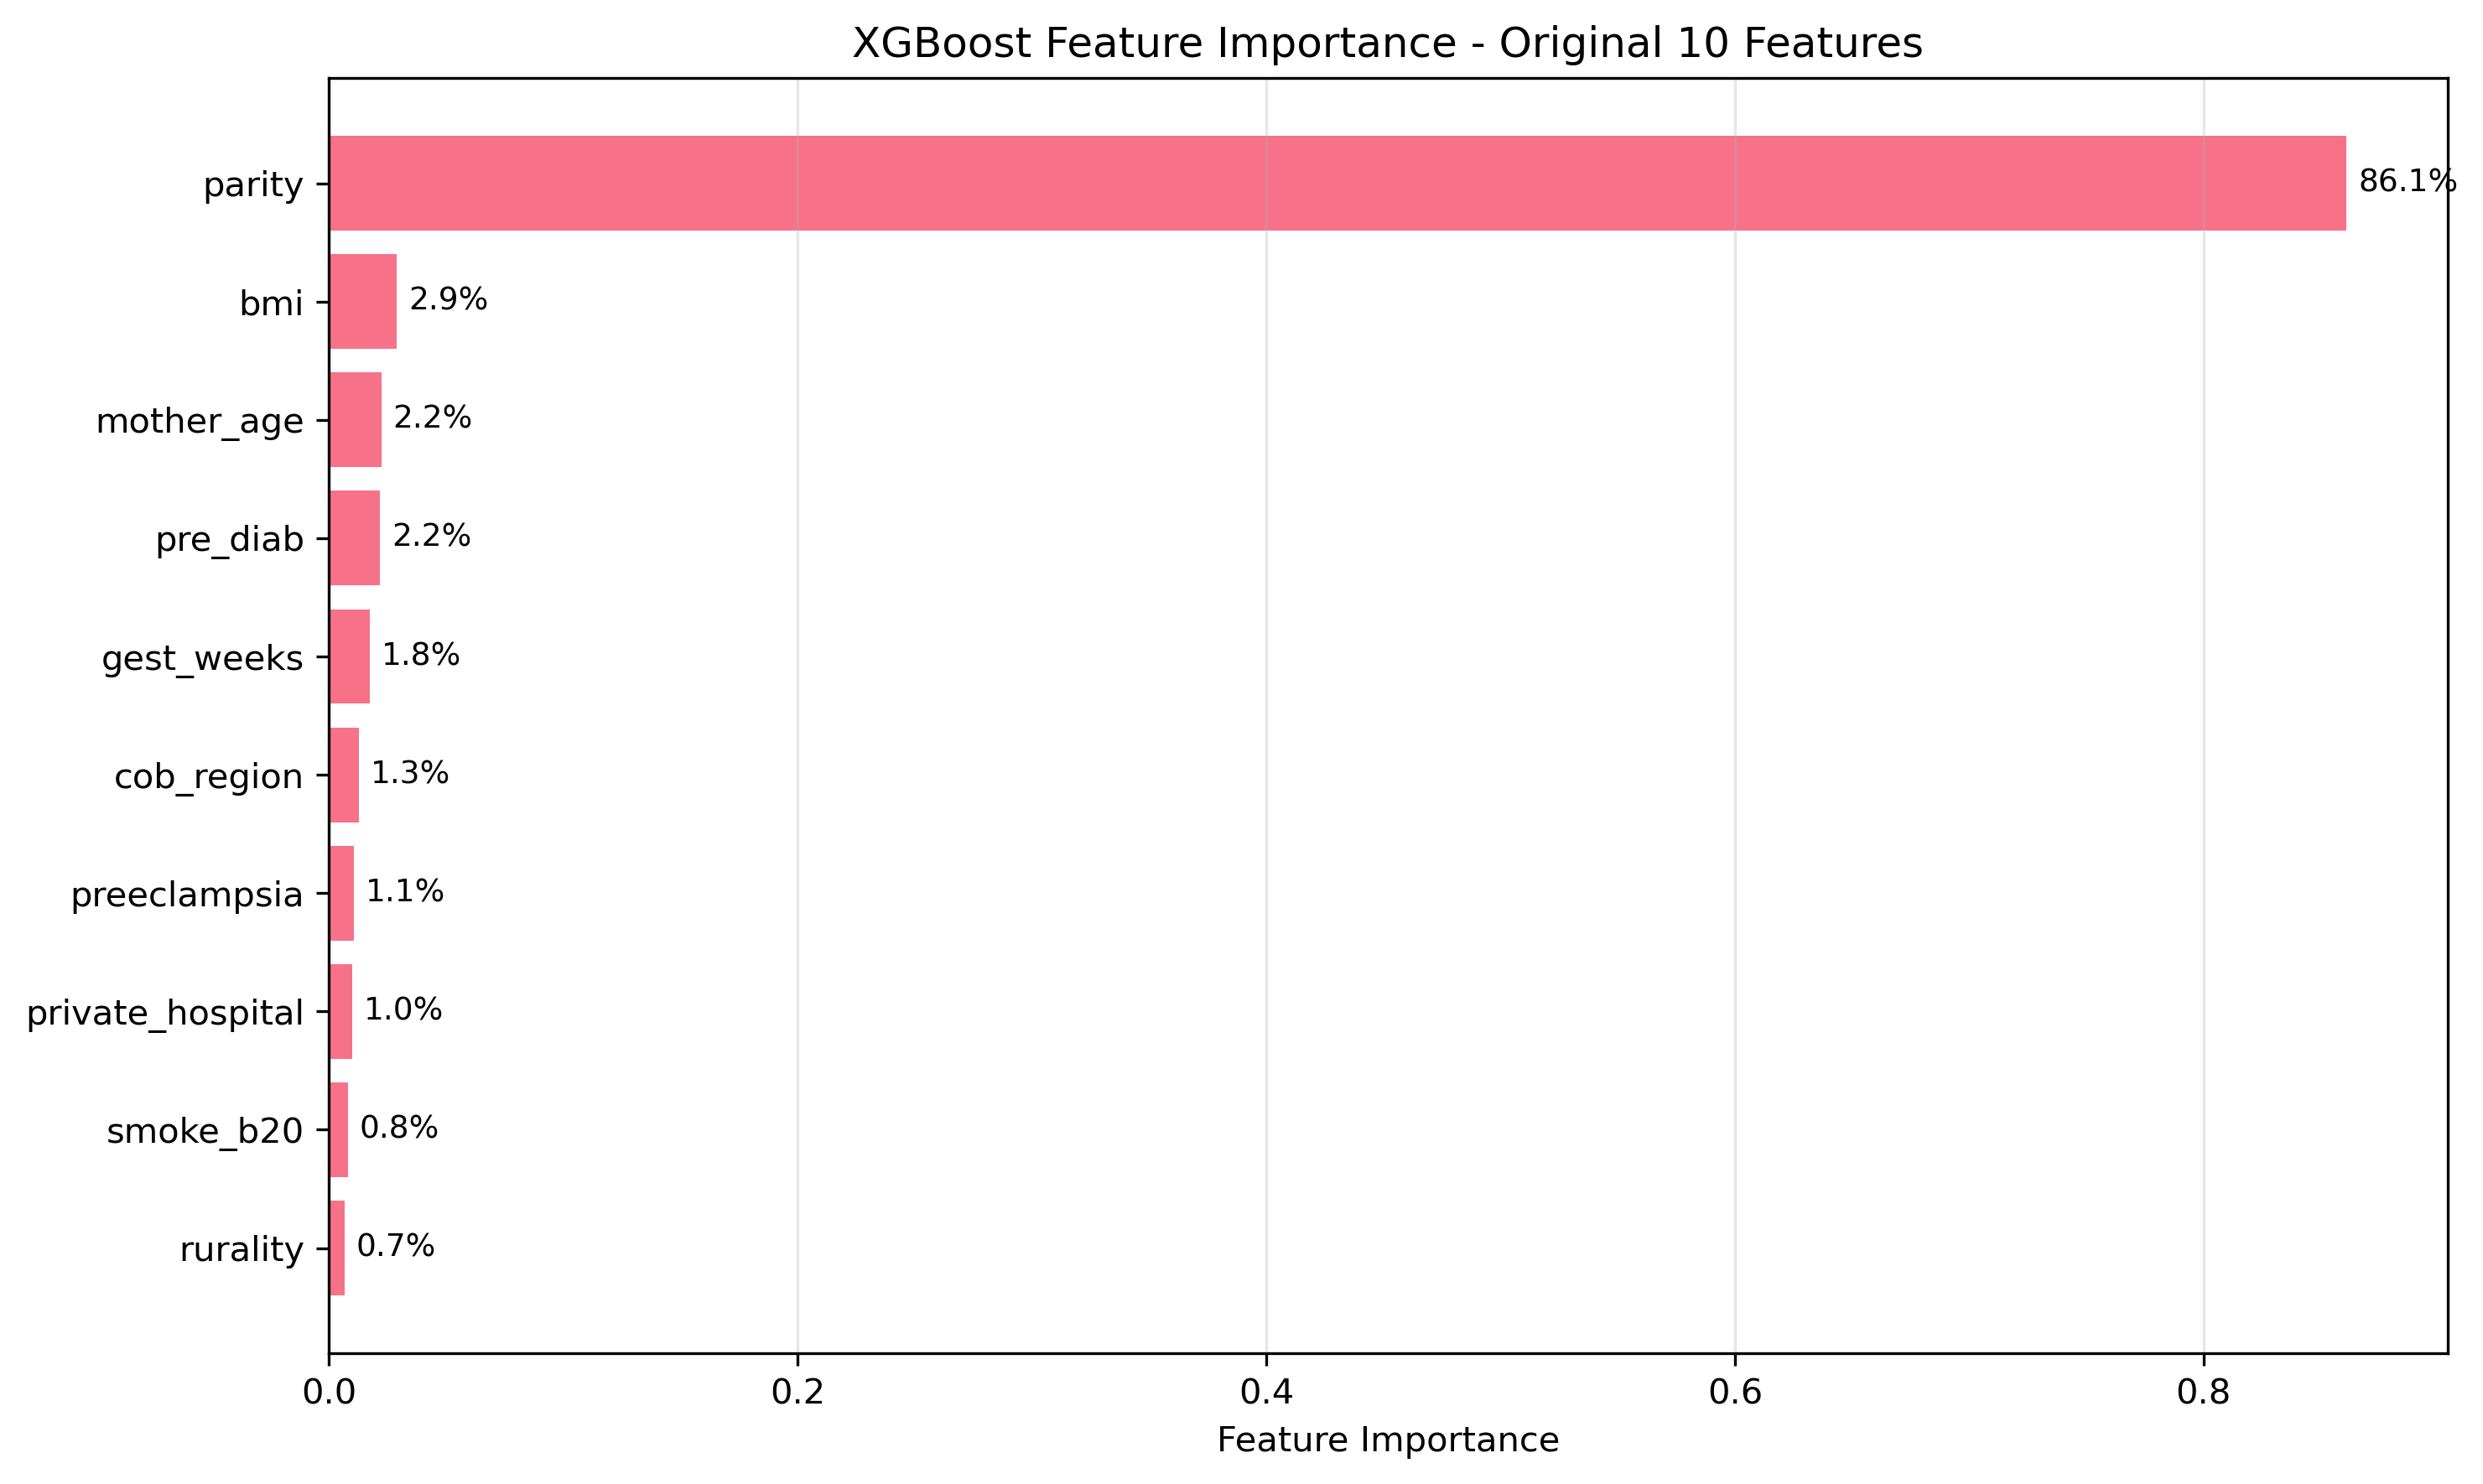


Feature Importance Summary:
Most important feature: parity (0.8610)
Least important feature: rurality (0.0066)
Top 3 features account for: 91.2% of importance
Parity dominance: 86.1% of total importance


In [172]:
# Print feature importance from the corrected pipeline

print("FEATURE IMPORTANCE")
print("="*50)

# Get feature importance from the XGBClassifier in the pipeline
xgb_classifier = corrected_pipeline.named_steps['classification']
feature_names = corrected_pipeline.named_steps['feature_selection'].original_features
feature_importance = xgb_classifier.feature_importances_

print(f"Number of features: {len(feature_names)}")
print(f"Feature importance shape: {feature_importance.shape}")

# Create feature importance pairs and sort by importance
feature_imp_pairs = list(zip(feature_names, feature_importance))
feature_imp_pairs = sorted(feature_imp_pairs, key=lambda x: x[1], reverse=True)

# Store original pairs for CSV export
feature_imp_pairs_original = feature_imp_pairs.copy()  

print("-" * 45)
print(f"{'Feature':<20} {'Importance':<12} {'Percentage'}")
print("-" * 45)

total_importance = sum(feature_importance)
for i, (feature, importance) in enumerate(feature_imp_pairs, 1):
    percentage = (importance / total_importance) * 100
    print(f"{i:2d}. {feature:<17} {importance:8.4f}     {percentage:6.1f}%")

print("-" * 45)
print(f"{'Total':<20} {total_importance:8.4f}     {100.0:6.1f}%")


# Save feature importance data to CSV
pd.DataFrame(feature_imp_pairs_original,
             columns=["Feature", "Importance"]).to_csv(
    "feature_importance_original.csv", index=False)

# Visualize feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
features, importances = zip(*feature_imp_pairs)
y_pos = range(len(features))

plt.barh(y_pos, importances)
plt.yticks(y_pos, features)
plt.xlabel('Feature Importance')
plt.title('XGBoost Feature Importance - Original 10 Features')
plt.gca().invert_yaxis()  # Highest importance at top

# Add percentage labels on bars
for i, (feature, importance) in enumerate(feature_imp_pairs):
    percentage = (importance / total_importance) * 100
    plt.text(importance + 0.005, i, f'{percentage:.1f}%', 
             va='center', fontsize=9)

plt.tight_layout()
plt.grid(axis='x', alpha=0.3)
plt.show()

# Summary statistics
print(f"\nFeature Importance Summary:")
print(f"Most important feature: {feature_imp_pairs[0][0]} ({feature_imp_pairs[0][1]:.4f})")
print(f"Least important feature: {feature_imp_pairs[-1][0]} ({feature_imp_pairs[-1][1]:.4f})")
print(f"Top 3 features account for: {sum([imp for _, imp in feature_imp_pairs[:3]])/total_importance*100:.1f}% of importance")

# Check if parity dominates (as expected)
parity_importance = next(imp for feat, imp in feature_imp_pairs if feat == 'parity')
print(f"Parity dominance: {parity_importance/total_importance*100:.1f}% of total importance")

AUC ANALYSIS WITH CONFIDENCE INTERVALS
Calculating bootstrap confidence intervals...
Original AUC: 0.7657
Bootstrap 95% CI: [0.7574, 0.7730]

Calculating optimism correction...
  Bootstrap 25/100
  Bootstrap 50/100
  Bootstrap 75/100
  Bootstrap 100/100

OPTIMISM CORRECTION RESULTS:
Original AUC: 0.7657
Mean optimism: -0.0001
Optimism-corrected AUC: 0.7658


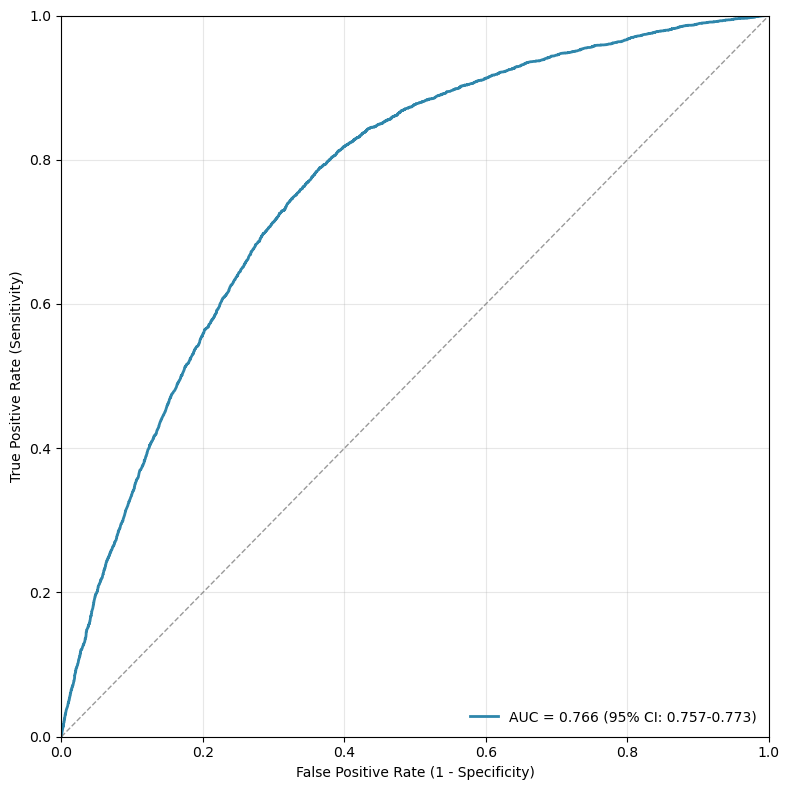


FINAL RESULTS:
AUC: 0.766 (95% CI: 0.757-0.773)
Optimism-corrected AUC: 0.766


In [20]:
# Calculate 95% CI for AUC and plot ROC curve

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.utils import resample
from sklearn.pipeline import Pipeline

print("AUC ANALYSIS WITH CONFIDENCE INTERVALS")
print("="*60)

# 1. Calculate 95% CI for AUC using bootstrap
def bootstrap_auc_ci(y_true, y_scores, n_bootstraps=1000, confidence_level=0.95):
    """Calculate bootstrap confidence interval for AUC"""
    np.random.seed(42)  # For reproducibility
    bootstrapped_aucs = []
    
    n_samples = len(y_true)
    
    for i in range(n_bootstraps):
        # Bootstrap sample
        indices = resample(range(n_samples), n_samples=n_samples)
        y_true_boot = y_true.iloc[indices] if hasattr(y_true, 'iloc') else y_true[indices]
        y_scores_boot = y_scores[indices]
        
        # Calculate AUC for bootstrap sample
        try:
            auc_boot = roc_auc_score(y_true_boot, y_scores_boot)
            bootstrapped_aucs.append(auc_boot)
        except:
            continue
    
    # Calculate confidence interval
    alpha = 1 - confidence_level
    lower_percentile = (alpha/2) * 100
    upper_percentile = (1 - alpha/2) * 100
    
    ci_lower = np.percentile(bootstrapped_aucs, lower_percentile)
    ci_upper = np.percentile(bootstrapped_aucs, upper_percentile)
    
    return np.array(bootstrapped_aucs), ci_lower, ci_upper

# Calculate original AUC
original_auc = roc_auc_score(y_true, y_pred_proba[:, 1])

# Bootstrap 95% CI for AUC
print("Calculating bootstrap confidence intervals...")
bootstrapped_aucs, ci_lower, ci_upper = bootstrap_auc_ci(y_true, y_pred_proba[:, 1])

print(f"Original AUC: {original_auc:.4f}")
print(f"Bootstrap 95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

# 2. Simplified optimism correction using the original model directly
def simple_optimism_correction(model, X, y, n_bootstraps=100):
    """Simplified optimism correction using the trained model"""
    np.random.seed(42)
    
    # Original model performance
    auc_orig = roc_auc_score(y, y_pred_proba[:, 1])
    
    optimism_values = []
    
    print("Calculating optimism correction...")
    for i in range(n_bootstraps):
        if (i + 1) % 25 == 0:
            print(f"  Bootstrap {i+1}/{n_bootstraps}")
        
        try:
            # Bootstrap sample
            n_samples = len(y)
            boot_indices = resample(range(n_samples), n_samples=n_samples)
            
            # Get bootstrap predictions
            y_boot = y.iloc[boot_indices] if hasattr(y, 'iloc') else y[boot_indices]
            y_pred_boot = y_pred_proba[boot_indices, 1]
            
            # Performance on bootstrap sample (apparent)
            auc_boot_apparent = roc_auc_score(y_boot, y_pred_boot)
            
            # Performance on original sample (test)
            auc_boot_test = auc_orig
            
            # Optimism = apparent - test
            optimism = auc_boot_apparent - auc_boot_test
            optimism_values.append(optimism)
            
        except Exception as e:
            continue
    
    if len(optimism_values) > 0:
        mean_optimism = np.mean(optimism_values)
        auc_corrected = auc_orig - mean_optimism
    else:
        mean_optimism = 0
        auc_corrected = auc_orig
    
    return auc_corrected, mean_optimism, optimism_values

# Calculate optimism-corrected AUC
print(f"\n" + "="*60)
auc_corrected, mean_optimism, optimism_values = simple_optimism_correction(
    corrected_pipeline, X_val, y_true, n_bootstraps=100
)

print(f"\nOPTIMISM CORRECTION RESULTS:")
print(f"Original AUC: {original_auc:.4f}")
print(f"Mean optimism: {mean_optimism:.4f}")
print(f"Optimism-corrected AUC: {auc_corrected:.4f}")

# 3. Create ROC curve plot
plt.figure(figsize=(8, 8))

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba[:, 1])

# Plot ROC curve
plt.plot(fpr, tpr, linewidth=2, color='#2E86AB', 
         label=f'AUC = {original_auc:.3f} (95% CI: {ci_lower:.3f}-{ci_upper:.3f})')
plt.plot([0, 1], [0, 1], '--', linewidth=1, color='gray', alpha=0.8)

# Formatting
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('')
plt.legend(loc='lower right', frameon=False)
plt.grid(True, alpha=0.3)
plt.xlim([0, 1])
plt.ylim([0, 1])

plt.tight_layout()
plt.show()

print(f"\nFINAL RESULTS:")
print(f"AUC: {original_auc:.3f} (95% CI: {ci_lower:.3f}-{ci_upper:.3f})")
if not np.isnan(auc_corrected):
    print(f"Optimism-corrected AUC: {auc_corrected:.3f}")
else:
    print("Optimism-corrected AUC: Could not calculate")

In [21]:
# 95% CIs for the calibration metrics using bootstrap
from sklearn.metrics import brier_score_loss

np.random.seed(123)
B, n = 1000, len(y_true)
y, p = np.asarray(y_true), np.asarray(pred_prob)
results = []

for _ in range(B):
    i = np.random.choice(n, n, replace=True)
    yi, pi = y[i], p[i]
    if len(np.unique(yi)) < 2:
        continue
    try:
        lp = logit(np.clip(pi, 1e-15, 1-1e-15))
        ci = sm.GLM(yi, np.ones((n, 1)),
                    family=sm.families.Binomial(), offset=lp).fit().params[0]
        cs = sm.Logit(yi, sm.add_constant(lp)).fit(disp=False).params[1]
        results.append([brier_score_loss(yi, pi), ci,
                        cs, yi.sum() / pi.sum()])
    except Exception:
        continue

boot = np.asarray(results)
ci_low, ci_high = np.percentile(boot, [2.5, 97.5], axis=0)

metrics = ["Brier Score", "Calibration Intercept",
           "Calibration Slope", "O/E Ratio"]
estimates = [brier, calibration_intercept, calibration_slope, oe_ratio]

for j, (name, est) in enumerate(zip(metrics, estimates)):
    print(f"{name}: {est:.3f} ({ci_low[j]:.3f}-{ci_high[j]:.3f})")

Brier Score: 0.159 (0.156-0.162)
Calibration Intercept: 0.222 (0.187-0.258)
Calibration Slope: 1.025 (0.984-1.063)
O/E Ratio: 1.155 (1.130-1.182)


MODEL CALIBRATION


/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_34331/2873860419.py:26: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  calibration_intercept = intercept_model.params[0]
/var/folders/z_/zldx_mrj6hn2607j6zy2pyqm0000gn/T/ipykernel_34331/2873860419.py:30: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  calibration_slope = slope_model.params[1]


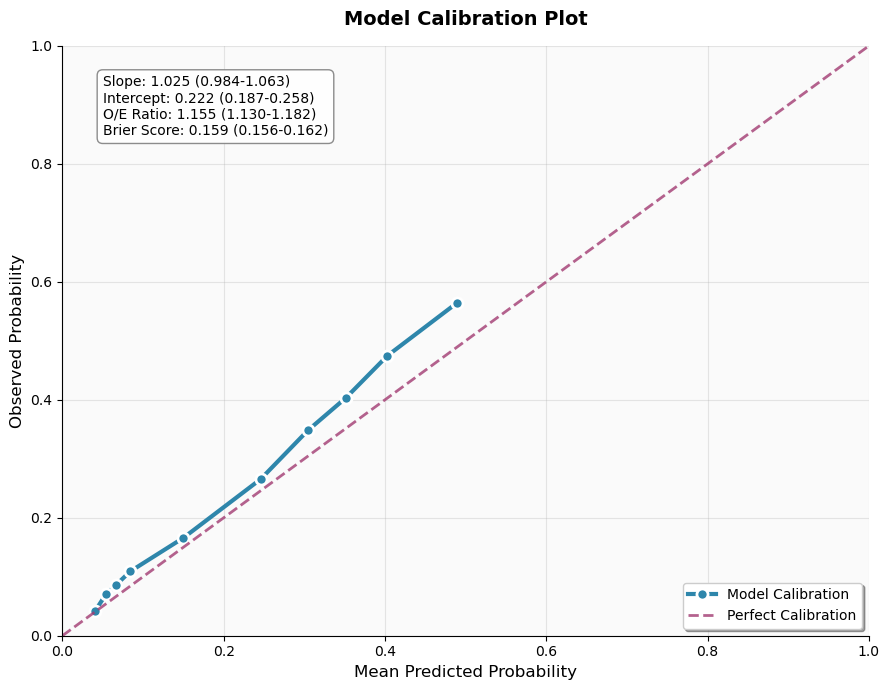

Brier Score: 0.1591
Calibration Intercept: 0.222
Calibration Slope: 1.025
O/E Ratio: 1.155

Calibration by Deciles:
   Decile  Observed  Predicted
0       1    0.0419     0.0405
1       2    0.0701     0.0539
2       3    0.0856     0.0661
3       4    0.1091     0.0841
4       5    0.1660     0.1501
5       6    0.2655     0.2458
6       7    0.3479     0.3043
7       8    0.4038     0.3519
8       9    0.4747     0.4030
9      10    0.5645     0.4895

Assessment - Slope: ✓ Good, Intercept: ⚠ Bias


In [22]:
# Model Calibration plot

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import statsmodels.api as sm
from scipy.special import logit

print("="*60)
print("MODEL CALIBRATION")
print("="*60)

# Calculate calibration metrics
pred_prob = y_pred_proba[:, 1]
brier = brier_score_loss(y_true, pred_prob)

# Calibration intercept and slope
eps = 1e-15
p = np.clip(pred_prob, eps, 1-eps)
offset = logit(p)

intercept_model = sm.GLM(y_true, np.ones((len(y_true),1)), 
                        family=sm.families.Binomial(), offset=offset).fit()
calibration_intercept = intercept_model.params[0]

X = sm.add_constant(offset)
slope_model = sm.Logit(y_true, X).fit(disp=False)
calibration_slope = slope_model.params[1]

# O/E ratio
oe_ratio = np.sum(y_true) / np.sum(pred_prob)

# Calibration curve
prob_true, prob_pred = calibration_curve(y_true, pred_prob, n_bins=10, strategy="quantile")

# Enhanced calibration plot
fig, ax = plt.subplots(figsize=(9, 7))

# Plot calibration curve
ax.plot(prob_pred, prob_true, 'o-', linewidth=3, markersize=8, 
        color='#2E86AB', markerfacecolor='#2E86AB', markeredgecolor='white', 
        markeredgewidth=2, label='Model Calibration')

# Perfect calibration line
ax.plot([0, 1], [0, 1], '--', color='#A23B72', linewidth=2, 
        alpha=0.8, label='Perfect Calibration')

# Styling
ax.set_xlabel("Mean Predicted Probability", fontsize=12)
ax.set_ylabel("Observed Probability", fontsize=12)
ax.set_title("Model Calibration Plot", fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)

# Metrics text box
metrics_text = (
    f'Slope: {calibration_slope:.3f} ({ci_low[2]:.3f}-{ci_high[2]:.3f})\n'
    f'Intercept: {calibration_intercept:.3f} ({ci_low[1]:.3f}-{ci_high[1]:.3f})\n'
    f'O/E Ratio: {oe_ratio:.3f} ({ci_low[3]:.3f}-{ci_high[3]:.3f})\n'
    f'Brier Score: {brier:.3f} ({ci_low[0]:.3f}-{ci_high[0]:.3f})'
)

ax.text(0.05, 0.95, metrics_text, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=dict(boxstyle="round,pad=0.4",
        facecolor="white", edgecolor="gray", alpha=0.9))

# Legend
ax.legend(loc='lower right', frameon=True, fancybox=True, shadow=True)

# Clean styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_facecolor('#fafafa')

plt.tight_layout()
plt.show()

# Print results
print(f"Brier Score: {brier:.4f}")
print(f"Calibration Intercept: {calibration_intercept:.3f}")
print(f"Calibration Slope: {calibration_slope:.3f}")
print(f"O/E Ratio: {oe_ratio:.3f}")

# Calibration table
calibration_df = pd.DataFrame({
    "Decile": range(1, 11),
    "Observed": prob_true,
    "Predicted": prob_pred
})

print(f"\nCalibration by Deciles:")
print(calibration_df.round(4))

# Assessment
slope_ok = "✓ Good" if abs(calibration_slope - 1.0) < 0.1 else "⚠ Check"
intercept_ok = "✓ Good" if abs(calibration_intercept) < 0.1 else "⚠ Bias"
print(f"\nAssessment - Slope: {slope_ok}, Intercept: {intercept_ok}")

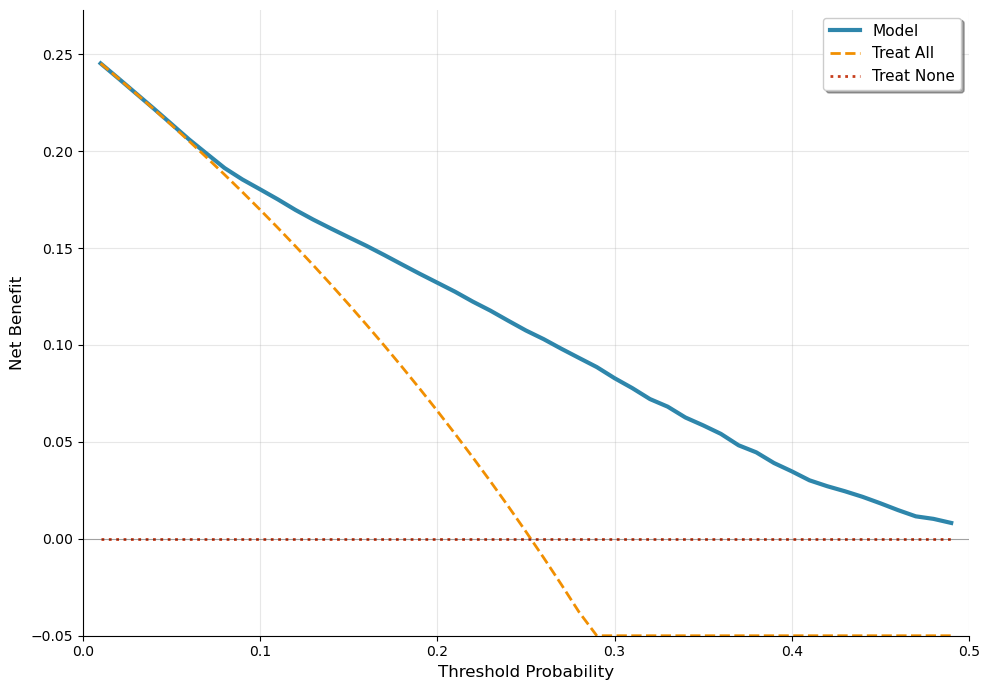

✓ Model outperforms 'Treat All': 0.02 to 0.49
✓ Optimal threshold: 0.02 (Net Benefit: 0.2375)
✓ Model outperforms 'Treat None': 0.01 to 0.49

Key thresholds and net benefits:
  0.05: Model NB = 0.2139
  0.10: Model NB = 0.1803
  0.15: Model NB = 0.1556
  0.20: Model NB = 0.1321
  0.25: Model NB = 0.1075
  0.30: Model NB = 0.0829


In [23]:
# Decision Curve Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


pred_prob = y_pred_proba[:, 1]
y = y_true.values if hasattr(y_true, "values") else y_true

def net_benefit(y_true, y_prob, threshold):
    """Calculate net benefit for given threshold"""
    if threshold >= 1.0 or threshold <= 0.0:
        return 0
    
    y_pred = (y_prob >= threshold).astype(int)
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    n = len(y_true)
    
    nb = (tp / n) - (fp / n) * (threshold / (1 - threshold))
    return nb

# Use clinically relevant threshold range only
thresholds = np.arange(0.01, 0.50, 0.01)  # Stop at 0.50

model_nb = []
all_nb = []
none_nb = []

event_rate = np.mean(y)

for t in thresholds:
    # Model net benefit
    model_nb.append(net_benefit(y, pred_prob, t))
    
    # Treat all strategy - clip negative values for visualization
    treat_all_nb = event_rate - (1 - event_rate) * (t / (1 - t))
    all_nb.append(max(treat_all_nb, -0.05))  # Don't let it go too negative
    
    # Treat none strategy
    none_nb.append(0)

model_nb = np.array(model_nb)
all_nb = np.array(all_nb)
none_nb = np.array(none_nb)

# Enhanced plot with proper scaling
fig, ax = plt.subplots(figsize=(10, 7))

# Plot curves
ax.plot(thresholds, model_nb, label="Model", linewidth=3, color='#2E86AB')
ax.plot(thresholds, all_nb, linestyle="--", label="Treat All", linewidth=2, color='#F18F01')
ax.plot(thresholds, none_nb, linestyle=":", label="Treat None", linewidth=2, color='#C73E1D')

# Better y-axis limits
max_nb = max(np.max(model_nb), event_rate)
ax.set_ylim(-0.05, max_nb + 0.02)  # Set reasonable limits
ax.set_xlim(0, 0.50)

# Styling
ax.set_xlabel("Threshold Probability", fontsize=12)
ax.set_ylabel("Net Benefit", fontsize=12)
ax.set_title("", fontsize=14, fontweight='bold', pad=15)

# Add reference line at y=0
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3, linewidth=0.8)

# Grid and legend
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True, fontsize=11)

# Clean styling
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Analysis with corrected calculations
net_benefit_df = pd.DataFrame({
    "threshold": thresholds,
    "model": model_nb,
    "treat_all": all_nb,
    "treat_none": none_nb
})

# Find where model is useful (without clipping for analysis)
original_all_nb = [event_rate - (1 - event_rate) * (t / (1 - t)) for t in thresholds]
net_benefit_df["treat_all_original"] = original_all_nb

better_than_all = net_benefit_df[net_benefit_df["model"] > net_benefit_df["treat_all_original"]]
better_than_none = net_benefit_df[net_benefit_df["model"] > 0]


if len(better_than_all) > 0:
    min_thresh = better_than_all['threshold'].min()
    max_thresh = better_than_all['threshold'].max()
    print(f"✓ Model outperforms 'Treat All': {min_thresh:.2f} to {max_thresh:.2f}")
    
    # Optimal threshold
    optimal_idx = better_than_all['model'].idxmax()
    optimal_threshold = net_benefit_df.loc[optimal_idx, 'threshold']
    optimal_nb = net_benefit_df.loc[optimal_idx, 'model']
    print(f"✓ Optimal threshold: {optimal_threshold:.2f} (Net Benefit: {optimal_nb:.4f})")
else:
    print("⚠ Model never outperforms 'Treat All' strategy")

if len(better_than_none) > 0:
    min_thresh_none = better_than_none['threshold'].min()
    max_thresh_none = better_than_none['threshold'].max()
    print(f"✓ Model outperforms 'Treat None': {min_thresh_none:.2f} to {max_thresh_none:.2f}")

# Show some key values
print(f"\nKey thresholds and net benefits:")
key_thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
for thresh in key_thresholds:
    if thresh in thresholds:
        idx = np.where(thresholds == thresh)[0][0]
        print(f"  {thresh:.2f}: Model NB = {model_nb[idx]:.4f}")

Calculating ROC metrics with 95% CI...
AUC: 0.7657 (95% CI: 0.7574-0.7730)


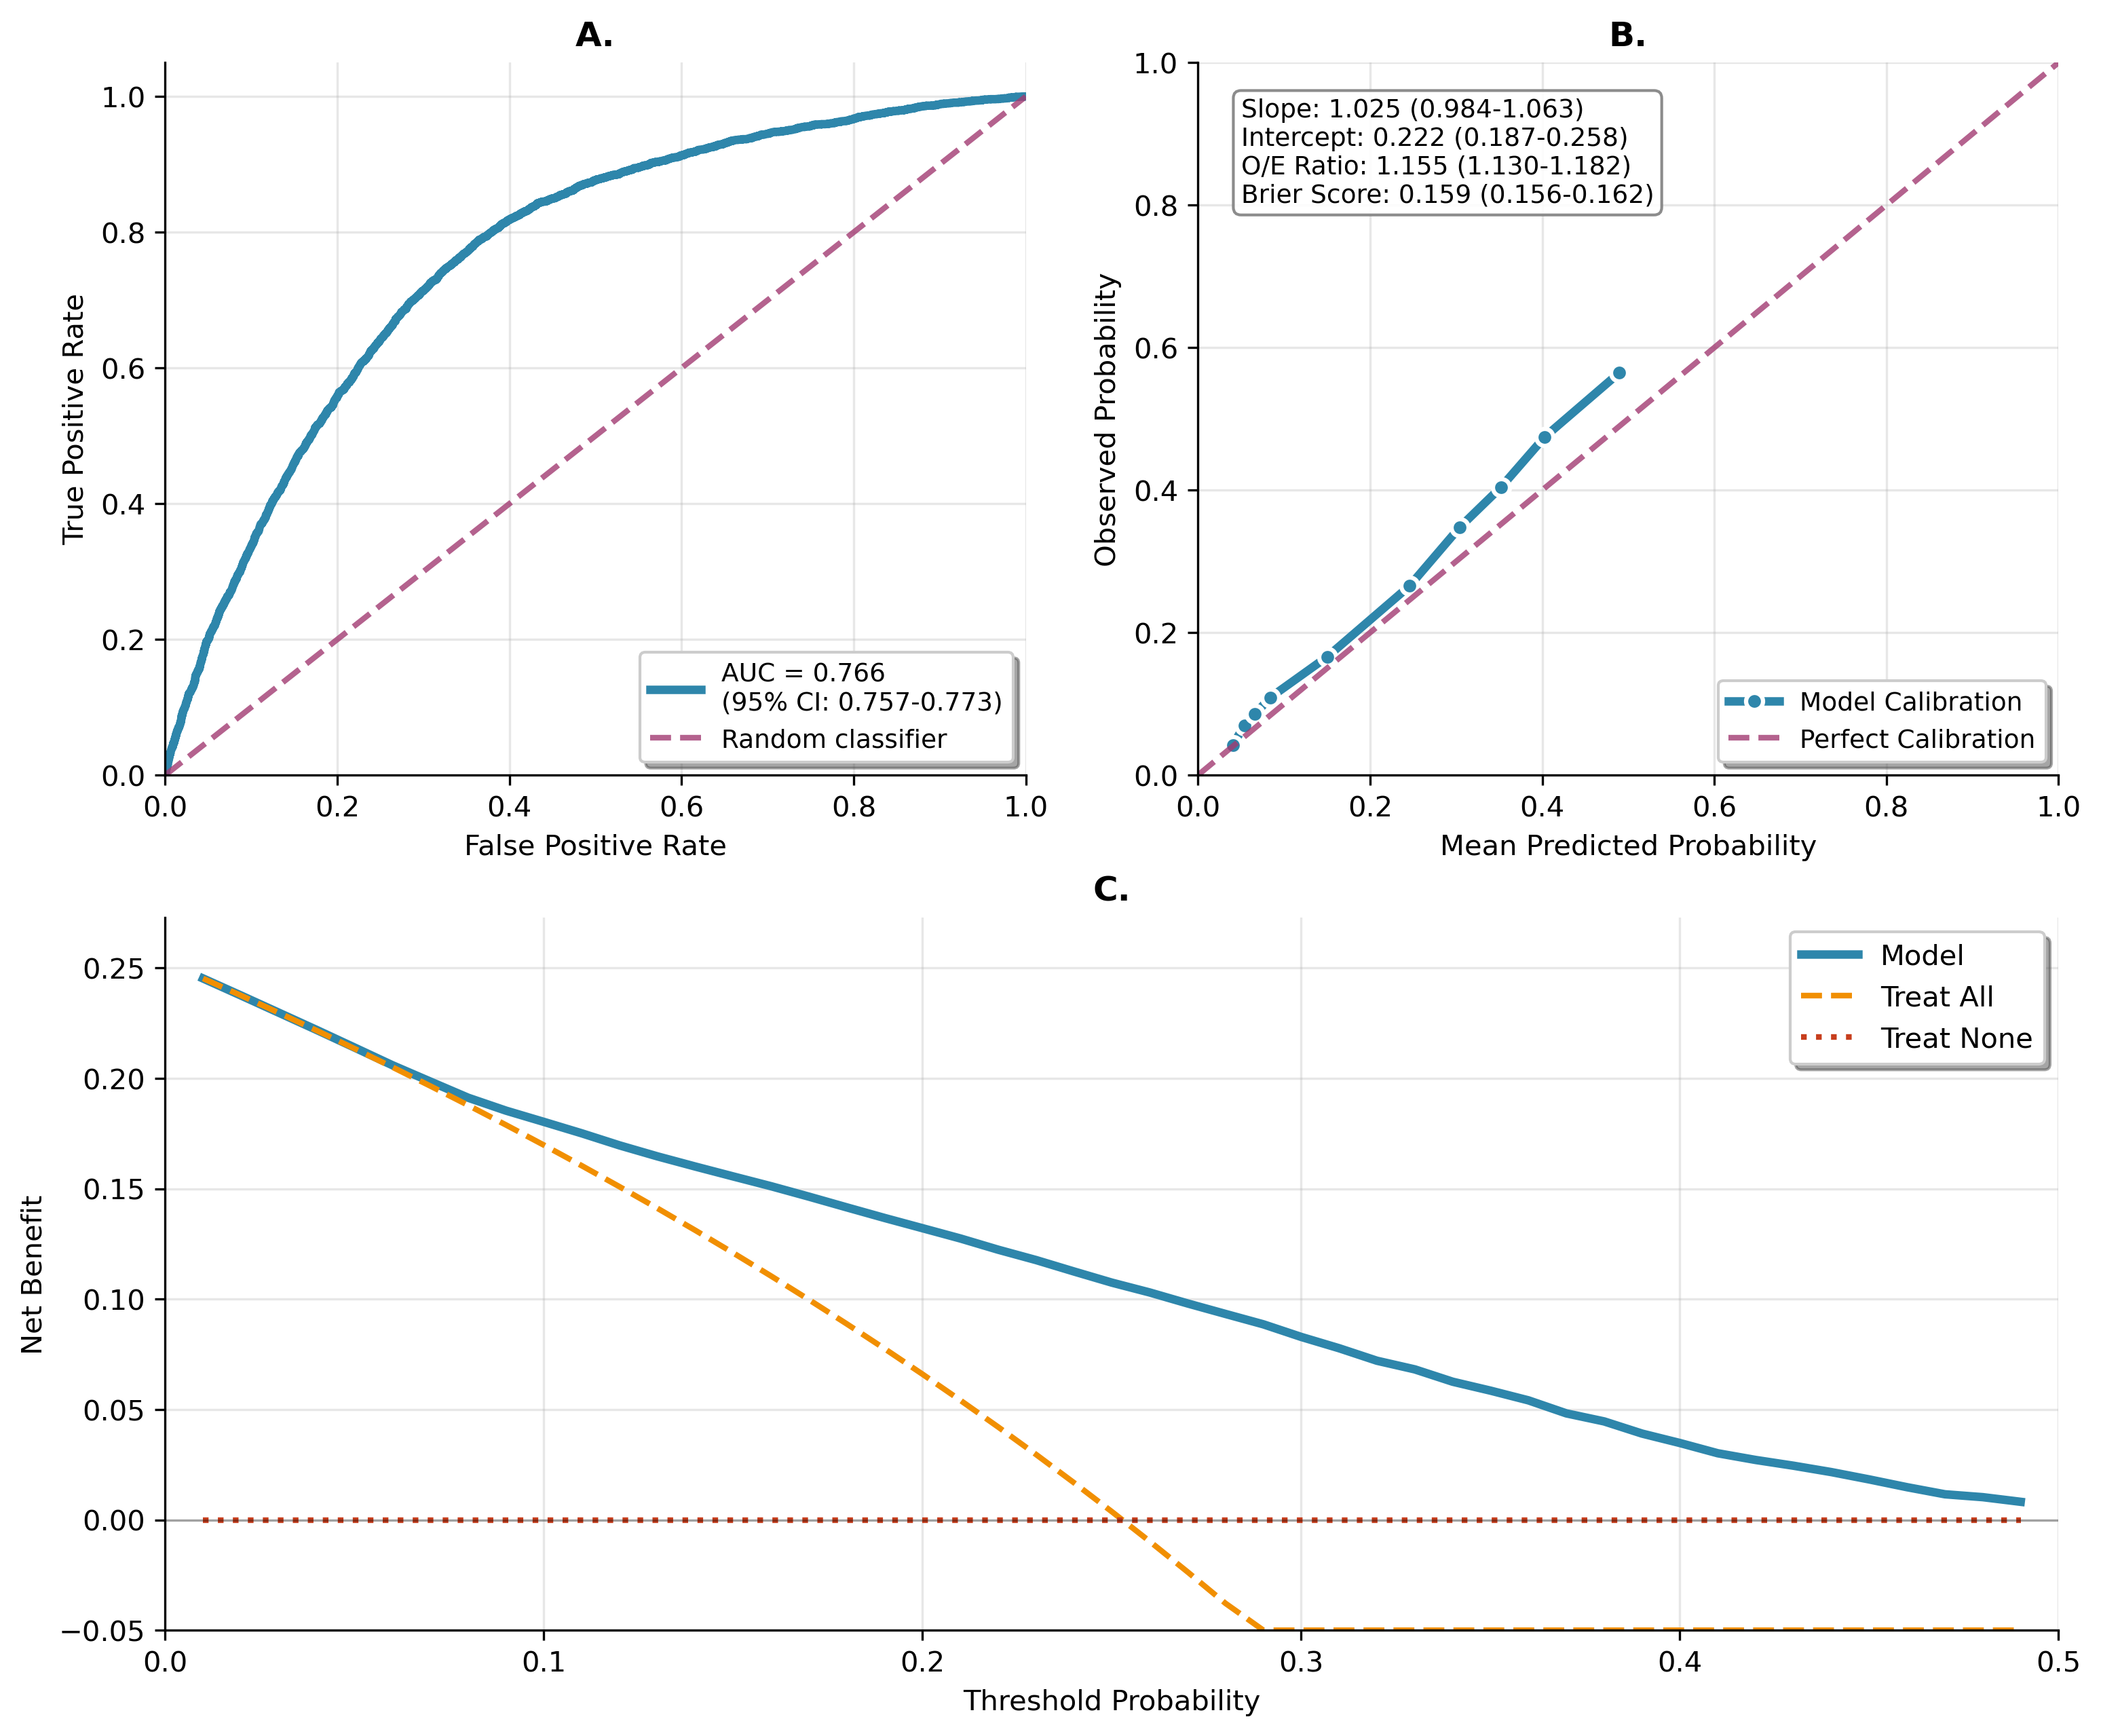

In [24]:
# Combine the 3 plots together in a grid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, roc_curve, auc, roc_auc_score
from sklearn.calibration import calibration_curve
from sklearn.utils import resample
import statsmodels.api as sm
from scipy.special import logit

# Set high-resolution parameters
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10

# Bootstrap function for AUC CI
def bootstrap_auc_ci(y_true, y_scores, n_bootstraps=1000, confidence_level=0.95):
    """Calculate bootstrap confidence interval for AUC"""
    np.random.seed(42)
    bootstrapped_aucs = []
    n_samples = len(y_true)
    
    for i in range(n_bootstraps):
        indices = resample(range(n_samples), n_samples=n_samples)
        y_true_boot = y_true.iloc[indices] if hasattr(y_true, 'iloc') else y_true[indices]
        y_scores_boot = y_scores[indices]
        
        try:
            auc_boot = roc_auc_score(y_true_boot, y_scores_boot)
            bootstrapped_aucs.append(auc_boot)
        except:
            continue
    
    alpha = 1 - confidence_level
    lower_percentile = (alpha/2) * 100
    upper_percentile = (1 - alpha/2) * 100
    
    ci_lower = np.percentile(bootstrapped_aucs, lower_percentile)
    ci_upper = np.percentile(bootstrapped_aucs, upper_percentile)
    
    return np.array(bootstrapped_aucs), ci_lower, ci_upper

# Calculate all metrics
pred_prob = y_pred_proba[:, 1]
y = y_true.values if hasattr(y_true, "values") else y_true

# ROC metrics with CI
print("Calculating ROC metrics with 95% CI...")
fpr, tpr, _ = roc_curve(y, pred_prob)
original_auc = roc_auc_score(y, pred_prob)
bootstrapped_aucs, ci_lower, ci_upper = bootstrap_auc_ci(y_true, pred_prob)

print(f"AUC: {original_auc:.4f} (95% CI: {ci_lower:.4f}-{ci_upper:.4f})")

# Calibration metrics
brier = brier_score_loss(y, pred_prob)
eps = 1e-15
p = np.clip(pred_prob, eps, 1-eps)
offset = logit(p)

intercept_model = sm.GLM(y, np.ones((len(y),1)), 
                        family=sm.families.Binomial(), offset=offset).fit()
calibration_intercept = intercept_model.params[0]

X = sm.add_constant(offset)
slope_model = sm.Logit(y, X).fit(disp=False)
calibration_slope = slope_model.params[1]

oe_ratio = np.sum(y) / np.sum(pred_prob)
prob_true, prob_pred = calibration_curve(y, pred_prob, n_bins=10, strategy="quantile")

# Bootstrap 95% CIs for calibration metrics
np.random.seed(123)
B, n = 1000, len(y)
boot = []

for _ in range(B):
    i = np.random.choice(n, n, replace=True)
    yi, pi = y[i], pred_prob[i]

    if len(np.unique(yi)) < 2:
        continue

    try:
        lp = logit(np.clip(pi, 1e-15, 1-1e-15))
        ci = sm.GLM(yi, np.ones((n, 1)),
                    family=sm.families.Binomial(), offset=lp).fit().params[0]
        cs = sm.Logit(yi, sm.add_constant(lp)).fit(disp=False).params[1]
        boot.append([brier_score_loss(yi, pi), ci,
                     cs, yi.sum() / pi.sum()])
    except Exception:
        continue

boot = np.asarray(boot)
ci_low, ci_high = np.percentile(boot, [2.5, 97.5], axis=0)

# Decision curve metrics
def net_benefit(y_true, y_prob, threshold):
    if threshold >= 1.0 or threshold <= 0.0:
        return 0
    y_pred = (y_prob >= threshold).astype(int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    n = len(y_true)
    nb = (tp / n) - (fp / n) * (threshold / (1 - threshold))
    return nb

thresholds = np.arange(0.01, 0.50, 0.01)
event_rate = np.mean(y)

model_nb = [net_benefit(y, pred_prob, t) for t in thresholds]
all_nb = [max(event_rate - (1 - event_rate) * (t / (1 - t)), -0.05) for t in thresholds]
none_nb = [0 for t in thresholds]

# Create combined figure
fig = plt.figure(figsize=(12, 10))

# Plot A: ROC Curve with 95% CI (top left)
ax1 = plt.subplot(2, 2, 1)
ax1.plot(fpr, tpr, color='#2E86AB', linewidth=3, 
         label=f'AUC = {original_auc:.3f}\n(95% CI: {ci_lower:.3f}-{ci_upper:.3f})')
ax1.plot([0, 1], [0, 1], color='#A23B72', linestyle='--', linewidth=2, alpha=0.8, 
         label='Random classifier')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('A.', fontweight='bold', fontsize=12)
ax1.legend(loc="lower right", frameon=True, fancybox=True, shadow=True, fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Plot B: Calibration Plot (top right)
ax2 = plt.subplot(2, 2, 2)
ax2.plot(prob_pred, prob_true, 'o-', linewidth=3, markersize=6, 
        color='#2E86AB', markerfacecolor='#2E86AB', markeredgecolor='white', 
        markeredgewidth=1.5, label='Model Calibration')
ax2.plot([0, 1], [0, 1], '--', color='#A23B72', linewidth=2, 
        alpha=0.8, label='Perfect Calibration')
ax2.set_xlabel('Mean Predicted Probability')
ax2.set_ylabel('Observed Probability')
ax2.set_title('B.', fontweight='bold', fontsize=12)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.grid(True, alpha=0.3)

# Metrics text box with 95% CIs
metrics_text = (
    f'Slope: {calibration_slope:.3f} ({ci_low[2]:.3f}-{ci_high[2]:.3f})\n'
    f'Intercept: {calibration_intercept:.3f} ({ci_low[1]:.3f}-{ci_high[1]:.3f})\n'
    f'O/E Ratio: {oe_ratio:.3f} ({ci_low[3]:.3f}-{ci_high[3]:.3f})\n'
    f'Brier Score: {brier:.3f} ({ci_low[0]:.3f}-{ci_high[0]:.3f})'
)

ax2.text(0.05, 0.95, metrics_text, transform=ax2.transAxes, fontsize=9,
        verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", 
        facecolor="white", edgecolor="gray", alpha=0.9))

ax2.legend(loc='lower right', frameon=True, fancybox=True, shadow=True, fontsize=9)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Plot C: Decision Curve Analysis (bottom, spanning both columns)
ax3 = plt.subplot(2, 1, 2)
ax3.plot(thresholds, model_nb, label="Model", linewidth=3, color='#2E86AB')
ax3.plot(thresholds, all_nb, linestyle="--", label="Treat All", linewidth=2, color='#F18F01')
ax3.plot(thresholds, none_nb, linestyle=":", label="Treat None", linewidth=2, color='#C73E1D')

max_nb = max(np.max(model_nb), event_rate)
ax3.set_ylim(-0.05, max_nb + 0.02)
ax3.set_xlim(0, 0.50)

ax3.set_xlabel('Threshold Probability')
ax3.set_ylabel('Net Benefit')
ax3.set_title('C.', fontweight='bold', fontsize=12)

ax3.axhline(y=0, color='black', linestyle='-', alpha=0.3, linewidth=0.8)
ax3.grid(True, alpha=0.3)
ax3.legend(loc='upper right', frameon=True, fancybox=True, shadow=True)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# Save as high-resolution TIFF
plt.savefig('model_performance_plots.tiff', 
           format='tiff', 
           dpi=300, 
           bbox_inches='tight',
           facecolor='white',
           edgecolor='none')